# Cryptocurrency Market Intelligence
**Course:** 23CSE351 — Foundations of Data Science  
**Dataset:** User-provided cryptocurrency market snapshots  
**Analysis style:** Exploratory data analysis, statistical testing, time-aware feature engineering, regression, and investor-friendly interpretation

---

## Executive Summary & Problem Statement

Cryptocurrency prices can move sharply, and a chart that looks persuasive is not necessarily evidence of a reliable trading opportunity. This case study evaluates 15 questions about momentum, volume, price timing, risk, stablecoins, liquidity, and drawdowns using the supplied dataset.

**Core question:** What patterns in the observed data are supported strongly enough to inform risk awareness, and which popular trading claims remain unproven?

### Objectives
1. Validate the dataset's coverage and sampling cadence before making time-based claims.
2. Clean and transform fields while retaining plausible extreme market observations.
3. Answer all 15 questions using the requested plot types where the available data supports them.
4. Explain each result in plain language, including the practical implication and limitations.
5. Use statistical tests and a leakage-aware regression model to evaluate whether historical features contain predictive information.

> **Important financial caveat:** This is historical analysis, not personalized financial advice. It cannot guarantee profits. The file contains snapshot prices and rolling 24-hour volume, but no OHLC candle high/low fields or transaction-level order book data. Therefore, true intrahour wick-downs, exact intraday price ranges, and definitive technical bull traps cannot be measured directly. Where needed, this notebook uses explicitly labeled snapshot-based proxies rather than pretending those quantities are available.

## 1. Dataset Architecture and Variable Dictionary

The supplied CSV uses these observed column names: `timestamp`, `name`, `symbol`, `price_usd`, `vol_24h`, `total_vol`, `chg_24h`, `chg_7d`, and `market_cap`.

The requested fields `change_1h` and OHLC hourly high/low are not present in the supplied file. We will not fabricate them. A valid one-step return can be calculated from adjacent price snapshots, but it is only treated as an approximately hourly return when the actual elapsed interval falls inside a stated tolerance.

## 2. Import Libraries and Environment Configuration

In [1]:
import os, sys, platform, warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.figsize": (10, 5.5),
    "figure.dpi": 110,
    "axes.titlesize": 13,
    "axes.labelsize": 10.5,
    "legend.fontsize": 9
})
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("Platform:", platform.platform())

Python: 3.14.0
pandas: 3.0.3
Platform: Windows-11-10.0.26200-SP0


## 3. Dataset Ingestion and Structural Inspection

In [2]:
CSV_PATH = "/mnt/data/cryptocurrency(1).csv"
if not os.path.exists(CSV_PATH):
    CSV_PATH = "cryptocurrency.csv"  # put the CSV beside this notebook if running elsewhere
raw = pd.read_csv(CSV_PATH)
print(f"Raw dataset: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
display(raw.head())
display(pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "missing_count": raw.isna().sum(),
    "missing_percent": (raw.isna().mean()*100).round(2),
    "unique_values": raw.nunique(dropna=True)
}))

Raw dataset: 109,130 rows × 9 columns


,timestamp,name,symbol,price_usd,vol_24h,total_vol,chg_24h,chg_7d,market_cap
0,2026-08-08 18:00:38,Tether,usdt,$1.00,"$24,098,637,487.00",46.38%,+0.00%,+0.00%,"$183,123,813,632"
1,2026-08-08 18:00:38,USDC,usdc,$1.00,"$5,284,980,002.00",10.17%,+0.00%,+0.00%,"$72,127,561,734"
2,2026-08-08 18:00:38,TRON,trx,$0.33,"$253,470,674.00",0.49%,+0.30%,+0.30%,"$31,166,769,472"
3,2026-08-08 18:00:38,Ethereum,eth,"$1,923.40","$4,457,742,635.00",8.58%,-0.50%,+2.70%,"$232,129,206,940"
4,2026-08-08 18:00:38,Bitcoin,btc,"$65,125.00","$14,403,905,634.00",27.72%,-0.30%,+3.10%,"$1,306,888,059,877"


,dtype,missing_count,missing_percent,unique_values
timestamp,str,0,0.0000,2573
name,str,0,0.0000,71
symbol,str,0,0.0000,71
price_usd,str,0,0.0000,26471
vol_24h,str,0,0.0000,104207
total_vol,str,0,0.0000,2860
chg_24h,str,0,0.0000,3584
chg_7d,str,0,0.0000,6676
market_cap,str,0,0.0000,104495


## 4. Data Preprocessing, Data Hygiene, and Quality Engineering

Cleaning rules:
- Parse timestamps consistently.
- Convert currency-formatted values such as `$1,234.00` into numeric values.
- Convert percentage strings such as `+2.70%` into percentage-point numbers (2.70).
- Drop rows with invalid timestamps, missing symbols, or nonpositive prices from price-based analysis.
- Remove exact duplicate records only.
- Retain extreme returns unless there is evidence they are invalid.
- Sort each coin chronologically and calculate elapsed time explicitly.

The source CSV does not provide a verifiable collection URL in the visible fields. Its provenance should therefore be documented as user-provided data with source details to be confirmed by the project team.

In [3]:
df = raw.copy()
required = ["timestamp", "name", "symbol", "price_usd", "vol_24h", "total_vol",
            "chg_24h", "chg_7d", "market_cap"]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Expected columns missing from supplied CSV: {missing}")

def parse_currency(s):
    return pd.to_numeric(s.astype(str).str.replace(r"[$,]", "", regex=True).str.strip(), errors="coerce")

def parse_percent(s):
    return pd.to_numeric(s.astype(str).str.replace("%", "", regex=False)
                         .str.replace("+", "", regex=False).str.strip(), errors="coerce")

df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce", utc=True)
for c in ["price_usd", "vol_24h", "market_cap"]:
    df[c] = parse_currency(df[c])
for c in ["total_vol", "chg_24h", "chg_7d"]:
    df[c] = parse_percent(df[c])
df["name"] = df["name"].astype("string").str.strip()
df["symbol"] = df["symbol"].astype("string").str.strip().str.lower()

rows_before = len(df)
exact_duplicates = int(df.duplicated().sum())
df = df.dropna(subset=["timestamp", "symbol", "price_usd"])
df = df[df["price_usd"] > 0].drop_duplicates()
df = df.sort_values(["symbol", "timestamp"]).reset_index(drop=True)
print(f"Rows before cleaning: {rows_before:,}")
print(f"Exact duplicate rows detected before dropping: {exact_duplicates:,}")
print(f"Rows retained: {len(df):,}")
print(f"Unique coins: {df['symbol'].nunique():,}")
print(f"Time range (UTC): {df['timestamp'].min()} to {df['timestamp'].max()}")
display(df[["price_usd", "vol_24h", "chg_24h", "chg_7d", "market_cap"]].describe().T)

Rows before cleaning: 109,130
Exact duplicate rows detected before dropping: 0
Rows retained: 105,997
Unique coins: 68
Time range (UTC): 2026-01-26 16:54:46+00:00 to 2026-08-08 18:00:38+00:00


,count,mean,std,min,25%,50%,75%,max
price_usd,"105,997.0000","2,486.5407","12,450.5015",0.0100,0.9900,1.1200,76.6600,"90,117.0000"
vol_24h,"105,997.0000","4,056,924,845.6797","15,068,134,201.2636",0.0000,"40,457,736.0000","178,882,371.0000","619,587,070.0000","340,480,486,199.0000"
chg_24h,"104,816.0000",-0.0550,4.5847,-60.0500,-1.4600,0.0000,0.9800,265.3600
chg_7d,"105,997.0000",0.4643,68.8301,-42.3700,-3.8700,-0.0100,1.7600,"6,153.5300"
market_cap,"105,997.0000","57,211,039,092.0481","220,571,790,553.8280","1,444,408,018.0000","2,681,206,931.0000","4,803,616,697.0000","12,029,676,112.0000","1,800,863,283,261.0000"


### 4.1 Sampling-frequency audit — a critical prerequisite

In [4]:
df["elapsed_hours"] = df.groupby("symbol")["timestamp"].diff().dt.total_seconds()/3600
intervals = df["elapsed_hours"].dropna()
print("Same-coin interval distribution, in hours:")
display(intervals.describe(percentiles=[.1,.25,.5,.75,.9,.95]).to_frame("elapsed_hours"))
print(f"Share of same-coin intervals between 0.5 and 1.5 hours: {((intervals>=.5)&(intervals<=1.5)).mean()*100:.1f}%")
print(f"Share between 21 and 27 hours: {((intervals>=21)&(intervals<=27)).mean()*100:.1f}%")

Same-coin interval distribution, in hours:


,elapsed_hours
count,"105,929.0000"
mean,1.4893
std,5.8451
min,0.0381
10%,0.3744
25%,0.4953
50%,0.7364
75%,1.3053
90%,3.6139
95%,4.2708


Share of same-coin intervals between 0.5 and 1.5 hours: 51.3%
Share between 21 and 27 hours: 0.1%


## 5. Exploratory Data Analysis (EDA) Overview

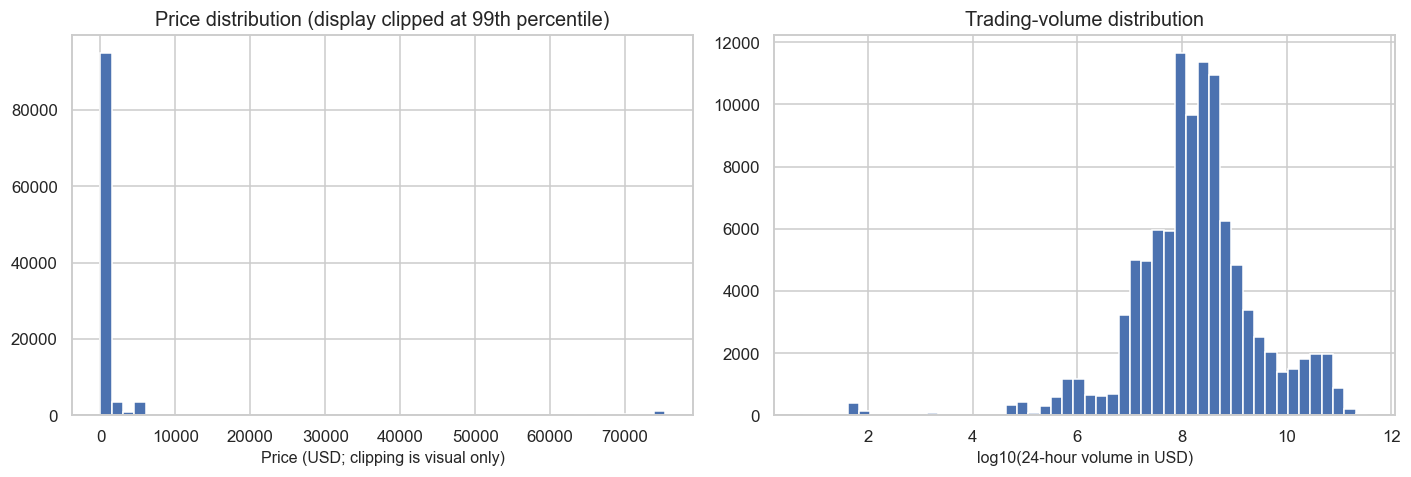

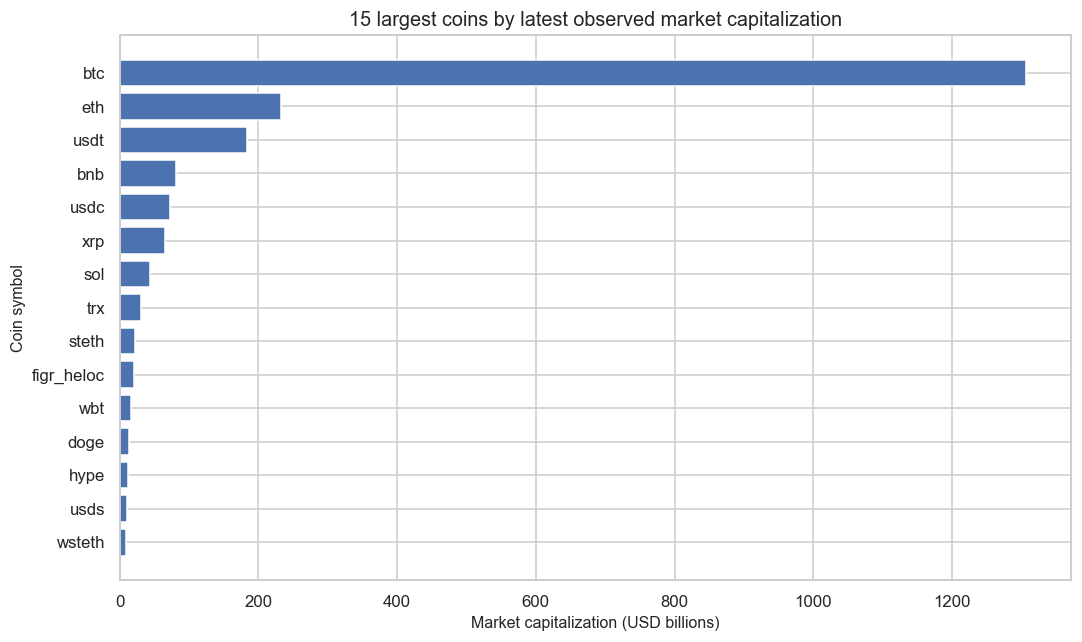

Interpretation: price, volume, and market capitalization have strongly different scales across coins. Log scales and market-cap groups help comparisons, but all charts below retain clear original units wherever practical.


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(df["price_usd"].clip(upper=df["price_usd"].quantile(.99)).dropna(), bins=50)
axes[0].set_title("Price distribution (display clipped at 99th percentile)")
axes[0].set_xlabel("Price (USD; clipping is visual only)")
valid_vol = df.loc[df["vol_24h"] > 0, "vol_24h"]
axes[1].hist(np.log10(valid_vol.dropna()), bins=50)
axes[1].set_title("Trading-volume distribution")
axes[1].set_xlabel("log10(24-hour volume in USD)")
plt.tight_layout()
plt.show()

latest = df.sort_values("timestamp").groupby("symbol", as_index=False).tail(1).copy()
top15 = latest.nlargest(15, "market_cap").sort_values("market_cap")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top15["symbol"], top15["market_cap"]/1e9)
ax.set_title("15 largest coins by latest observed market capitalization")
ax.set_xlabel("Market capitalization (USD billions)")
ax.set_ylabel("Coin symbol")
plt.tight_layout()
plt.show()

print("Interpretation: price, volume, and market capitalization have strongly different scales across coins. Log scales and market-cap groups help comparisons, but all charts below retain clear original units wherever practical.")

## 6. Time-aware feature engineering

The timestamps are not perfectly regular. We therefore match future observations to target horizons using an explicit time tolerance. A row shift alone is never assumed to mean one hour or one day.

- **Approximate one-step return:** change between adjacent snapshots, with the actual elapsed interval retained.
- **Valid ~1-hour return:** adjacent snapshots 0.5–1.5 hours apart.
- **Future ~24-hour return:** next available observation close to 24 hours after the current timestamp, within ±3 hours.
- **Future ~7-day return:** next observation close to 168 hours after the current timestamp, within ±8 hours.

These tolerances are analysis choices, not universal truths. The output reports the resulting sample sizes.

In [6]:
df = df.sort_values(["symbol", "timestamp"]).reset_index(drop=True)
df["elapsed_hours"] = df.groupby("symbol")["timestamp"].diff().dt.total_seconds()/3600
df["observed_return_pct"] = df.groupby("symbol")["price_usd"].pct_change()*100
df["approx_hourly_return_pct"] = np.where(df["elapsed_hours"].between(.5, 1.5),
                                          df["observed_return_pct"], np.nan)
df["date_utc"] = df["timestamp"].dt.floor("D")
df["hour_utc"] = df["timestamp"].dt.hour
df["weekday_utc"] = df["timestamp"].dt.day_name()

def add_future_return(data, horizon_hours, tolerance_hours):
    parts = []
    for sym, g in data.groupby("symbol", sort=False):
        g = g.sort_values("timestamp").copy()
        if len(g) < 2:
            continue
        seconds = g["timestamp"].astype("int64").to_numpy()/1e9
        target = seconds + horizon_hours*3600
        idx = np.searchsorted(seconds, target, side="left")
        valid = idx < len(g)
        pos = np.where(valid)[0]
        fidx = idx[valid]
        err = (seconds[fidx] - target[valid])/3600
        keep = np.abs(err) <= tolerance_hours
        pos, fidx, err = pos[keep], fidx[keep], err[keep]
        if len(pos) == 0:
            continue
        out = g.iloc[pos].copy()
        out["future_timestamp"] = g["timestamp"].to_numpy()[fidx]
        out[f"future_return_{horizon_hours}h_pct"] = (
            g["price_usd"].to_numpy()[fidx]/out["price_usd"].to_numpy()-1
        )*100
        out["future_time_error_hours"] = err
        parts.append(out)
    if not parts:
        return pd.DataFrame(columns=list(data.columns)+[f"future_return_{horizon_hours}h_pct","future_timestamp"])
    return pd.concat(parts, ignore_index=True)

ret1 = df[df["approx_hourly_return_pct"].notna()].copy()
ret24 = add_future_return(df, 24, 3)
ret168 = add_future_return(df, 168, 8)
print(f"Valid adjacent observations approximating one hour: {len(ret1):,}")
print(f"Valid future ~24-hour pairs: {len(ret24):,}")
print(f"Valid future ~7-day pairs: {len(ret168):,}")

Valid adjacent observations approximating one hour: 54,367
Valid future ~24-hour pairs: 0
Valid future ~7-day pairs: 0


# 7. Fifteen Core Research Questions

For each question, the notebook presents the requested visualization (or the closest honest proxy supported by the supplied fields), a calculated summary, an investor-friendly interpretation, and a limitation note. Event thresholds are operational definitions chosen for this case study; they should be stress-tested before any real strategy is considered.

## Q1. Is Recent 7-Day Momentum Associated with the Current 24-Hour Price Change?

**Question:** Do cryptocurrencies with stronger seven-day gains also tend to have positive 24-hour changes in the available snapshot?

**Columns:** `chg_7d`, `chg_24h`

**Method:** Compare the current 24-hour percentage change across seven-day momentum groups and measure their rank correlation. This is a snapshot-based association, not a forecast of future returns.

,observations,median_24h_change,positive_24h_pct,negative_24h_pct
momentum_group,,,,
≤ −5%,22593,-1.7000,30.8600,69.0300
−5 to 0%,36084,-0.0100,34.8900,52.0700
0 to 5%,31451,0.0200,56.4600,36.9400
5 to 10%,7873,0.7700,61.0600,38.8800
> 10%,6815,1.9900,67.2800,32.6000


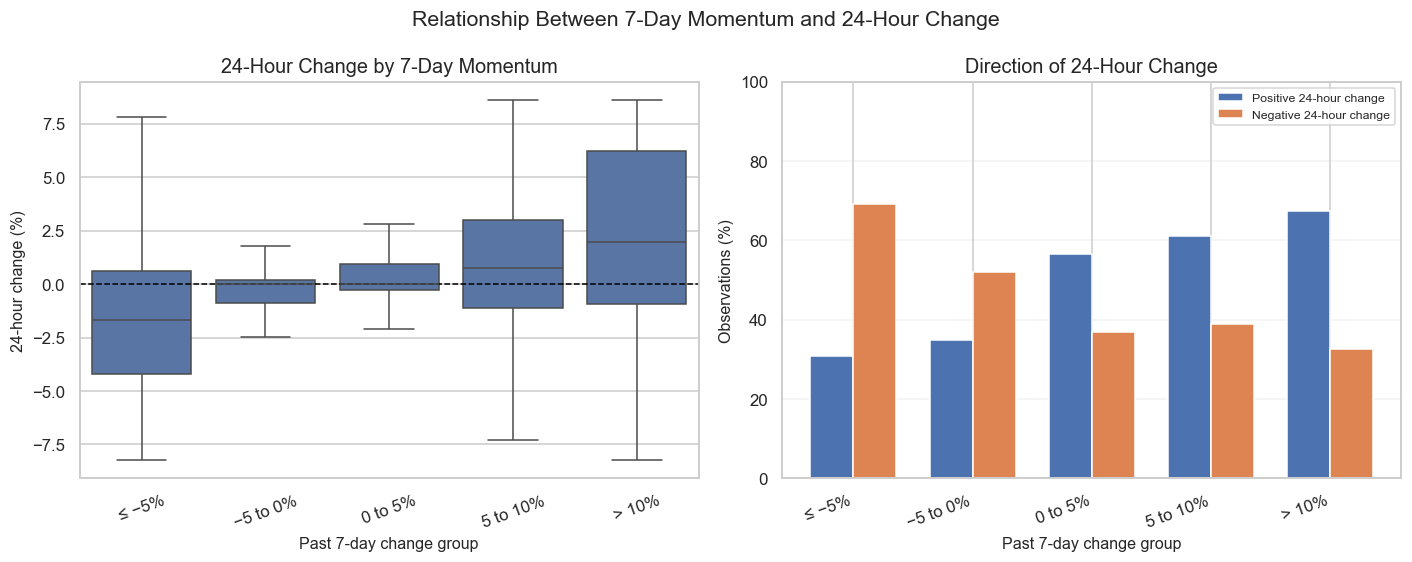

Spearman rank correlation: rho=0.311, p-value=0
Usable observations: 104,816
Highest median 24-hour change: > 10% (1.99%).
Lowest median 24-hour change: ≤ −5% (-1.70%).
Interpretation: this compares two reported snapshot metrics; it does not establish that past momentum predicts future returns.


In [7]:
# Q1: Seven-day momentum vs current 24-hour change
# The future-return matching can produce zero pairs when snapshots are irregular.
# This version uses the available chg_7d and chg_24h fields directly, so it can
# still answer a clearly defined snapshot-based question.

q1 = df[["symbol", "chg_7d", "chg_24h"]].copy()
q1["chg_7d"] = pd.to_numeric(q1["chg_7d"], errors="coerce")
q1["chg_24h"] = pd.to_numeric(q1["chg_24h"], errors="coerce")
q1 = q1.replace([np.inf, -np.inf], np.nan).dropna(subset=["chg_7d", "chg_24h"])

momentum_labels = ["≤ −5%", "−5 to 0%", "0 to 5%", "5 to 10%", "> 10%"]
q1["momentum_group"] = pd.cut(
    q1["chg_7d"],
    bins=[-np.inf, -5, 0, 5, 10, np.inf],
    labels=momentum_labels,
    include_lowest=True
)

q1_summary = q1.groupby("momentum_group", observed=False).agg(
    observations=("chg_24h", "count"),
    median_24h_change=("chg_24h", "median"),
    positive_24h_pct=("chg_24h", lambda s: (s > 0).mean() * 100),
    negative_24h_pct=("chg_24h", lambda s: (s < 0).mean() * 100)
).reindex(momentum_labels)

display(q1_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

# Left: distribution by momentum group; clip only for display so outliers don't flatten the plot
plot_data = q1.copy()
lower, upper = plot_data["chg_24h"].quantile([0.02, 0.98])
plot_data["chg_24h_display"] = plot_data["chg_24h"].clip(lower, upper)
sns.boxplot(
    data=plot_data, x="momentum_group", y="chg_24h_display",
    order=momentum_labels, showfliers=False, ax=axes[0]
)
axes[0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0].set_title("24-Hour Change by 7-Day Momentum")
axes[0].set_xlabel("Past 7-day change group")
axes[0].set_ylabel("24-hour change (%)")
axes[0].tick_params(axis="x", rotation=20)

# Right: percentage of positive and negative observations
x = np.arange(len(momentum_labels))
width = 0.36
pos = q1_summary["positive_24h_pct"].to_numpy(dtype=float)
neg = q1_summary["negative_24h_pct"].to_numpy(dtype=float)
axes[1].bar(x - width/2, pos, width, label="Positive 24-hour change")
axes[1].bar(x + width/2, neg, width, label="Negative 24-hour change")
axes[1].set_xticks(x, momentum_labels, rotation=20, ha="right")
axes[1].set_title("Direction of 24-Hour Change")
axes[1].set_xlabel("Past 7-day change group")
axes[1].set_ylabel("Observations (%)")
axes[1].set_ylim(0, 100)
axes[1].legend(fontsize=8)
axes[1].grid(axis="y", alpha=0.25)
axes[1].set_axisbelow(True)

fig.suptitle("Relationship Between 7-Day Momentum and 24-Hour Change", fontsize=14)
fig.tight_layout()
plt.show()

if len(q1) >= 3:
    rho, p_value = stats.spearmanr(q1["chg_7d"], q1["chg_24h"], nan_policy="omit")
    print(f"Spearman rank correlation: rho={rho:.3f}, p-value={p_value:.4g}")
print(f"Usable observations: {len(q1):,}")
if len(q1_summary.dropna(subset=["median_24h_change"])):
    highest = q1_summary["median_24h_change"].idxmax()
    lowest = q1_summary["median_24h_change"].idxmin()
    print(f"Highest median 24-hour change: {highest} ({q1_summary.loc[highest, 'median_24h_change']:.2f}%).")
    print(f"Lowest median 24-hour change: {lowest} ({q1_summary.loc[lowest, 'median_24h_change']:.2f}%).")
print("Interpretation: this compares two reported snapshot metrics; it does not establish that past momentum predicts future returns.")


### Insight

The markers highlight snapshots where trading volume was unusually high compared with that coin's previous observations. Check whether price also moved around those points.

**Conclusion:** A volume spike can signal increased market activity, but it does not by itself confirm a successful breakout or predict future returns.

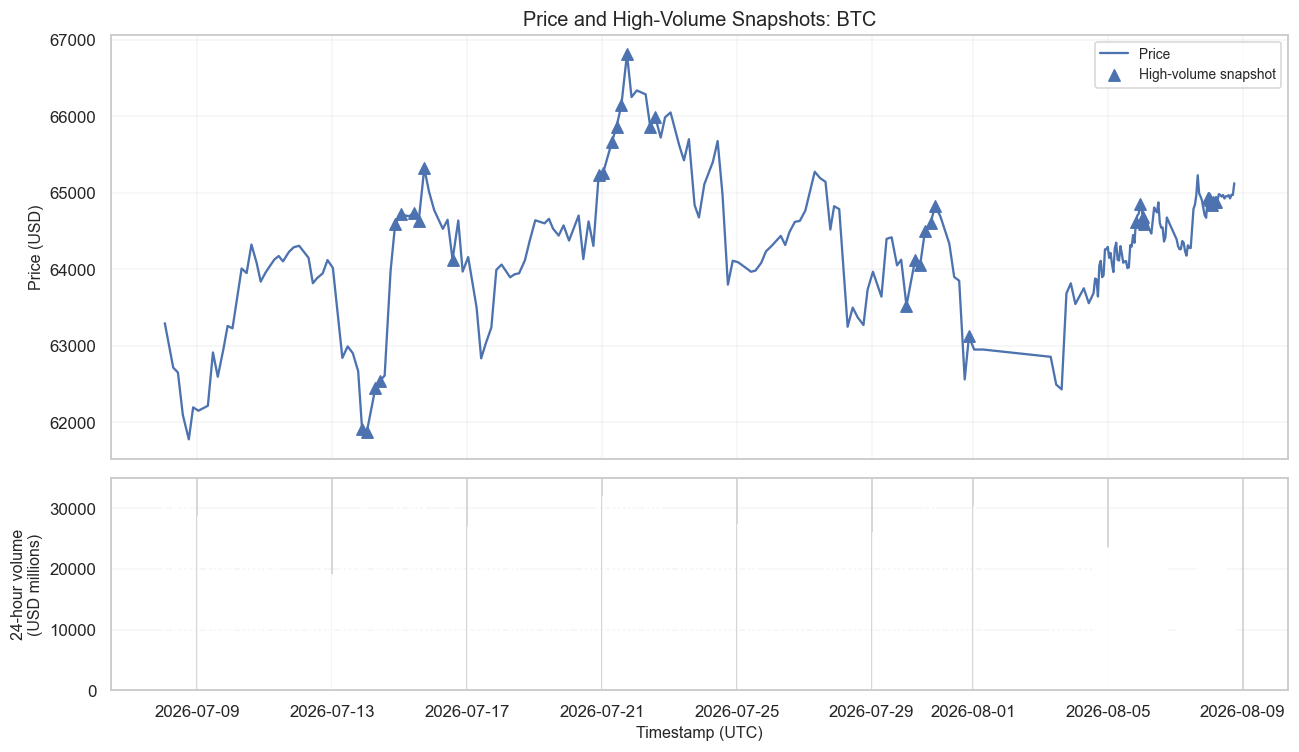

Snapshots plotted: 250; high-volume snapshots marked: 36.
Insight: markers identify snapshots whose volume exceeded the coin's prior rolling 90th-percentile volume. A volume spike alone does not prove a breakout; compare it with price movement and wider market context.


In [8]:
# Q2: Identify abnormal volume snapshots and visualize price/volume together.
# This version does not depend on future-return matching, which may be empty for irregular snapshots.

q2base = df[["symbol", "name", "timestamp", "price_usd", "vol_24h"]].copy()
q2base = q2base.sort_values(["symbol", "timestamp"])
q2base["prior_volume_q90"] = q2base.groupby("symbol")["vol_24h"].transform(
    lambda s: s.shift(1).rolling(24, min_periods=8).quantile(0.90)
)
q2base["volume_spike"] = (
    q2base["prior_volume_q90"].notna()
    & (q2base["vol_24h"] > q2base["prior_volume_q90"])
)

# Use the coin with the largest latest market cap for a readable example
chosen = latest.nlargest(1, "market_cap")["symbol"].iloc[0]
g = q2base[q2base["symbol"] == chosen].sort_values("timestamp").tail(250).copy()
sp = g[g["volume_spike"]]

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True,
                         gridspec_kw={"height_ratios": [2, 1]})
axes[0].plot(g["timestamp"], g["price_usd"], linewidth=1.5, label="Price")
if len(sp):
    axes[0].scatter(sp["timestamp"], sp["price_usd"], marker="^", s=55,
                    label="High-volume snapshot")
axes[0].set_title(f"Price and High-Volume Snapshots: {chosen.upper()}")
axes[0].set_ylabel("Price (USD)")
axes[0].legend()
axes[0].grid(alpha=0.2)

axes[1].bar(g["timestamp"], g["vol_24h"] / 1e6, width=0.025)
axes[1].set_ylabel("24-hour volume\n(USD millions)")
axes[1].set_xlabel("Timestamp (UTC)")
axes[1].grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

print(f"Snapshots plotted: {len(g):,}; high-volume snapshots marked: {len(sp):,}.")
print("Insight: markers identify snapshots whose volume exceeded the coin's prior rolling 90th-percentile volume. A volume spike alone does not prove a breakout; compare it with price movement and wider market context.")

## Q3. Profit-Taking Windows After a 10%+ Surge
**Question:** What does price do after a snapshot reports a 24-hour gain of at least 10%?

**Plot:** Average event-aligned future return curve.  
**Interpretation target:** pullback behavior, not a guaranteed exact selling time.

,events,mean_return,median_return,negative_share
horizon_hours,,,,
1,550,23.9400,13.8900,28.7300
3,149,85.5500,93.9900,20.8100


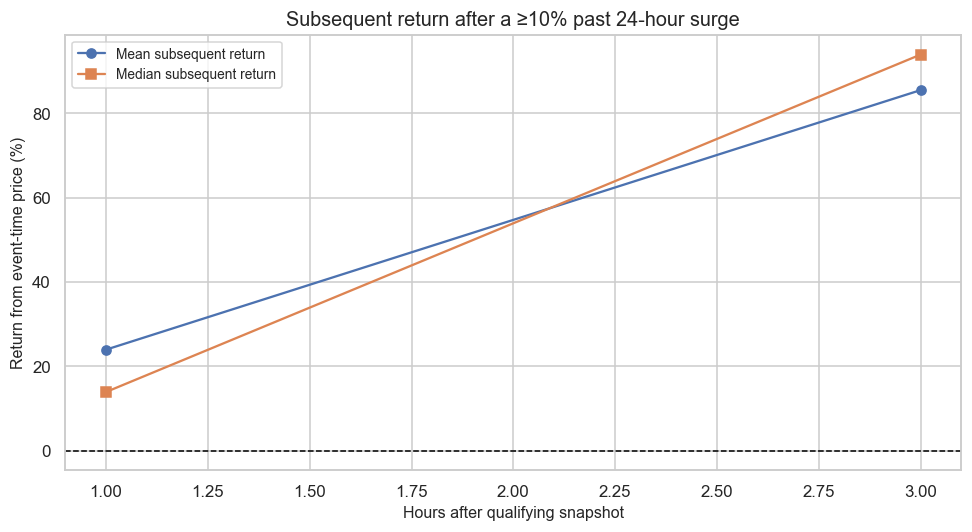

Investor interpretation: if the curve declines, surge events often give back some gains; if it stays positive, the average price remains above the event-time price. The exact top and optimal profit-taking minute cannot be identified from sparse snapshots.


In [9]:
surges=df[df["chg_24h"]>=10].copy()
trajectory=[]
for h,tol in [(1,.5),(3,1),(6,1.5),(12,2),(24,3)]:
    rr=add_future_return(surges,h,tol)
    col=f"future_return_{h}h_pct"
    if len(rr) and col in rr:
        trajectory.append(rr[["symbol","timestamp",col]].rename(columns={col:"future_return_pct"}).assign(horizon_hours=h))
if trajectory:
    traj=pd.concat(trajectory,ignore_index=True)
    summary=traj.groupby("horizon_hours")["future_return_pct"].agg(
        events="count",mean_return="mean",median_return="median",
        negative_share=lambda s:(s<0).mean()*100)
    display(summary.round(2))
    fig,ax=plt.subplots(figsize=(9,5))
    means=traj.groupby("horizon_hours")["future_return_pct"].mean()
    medians=traj.groupby("horizon_hours")["future_return_pct"].median()
    ax.plot(means.index,means.values,marker="o",label="Mean subsequent return")
    ax.plot(medians.index,medians.values,marker="s",label="Median subsequent return")
    ax.axhline(0,color="black",linestyle="--",linewidth=1)
    ax.set_title("Subsequent return after a ≥10% past 24-hour surge")
    ax.set_xlabel("Hours after qualifying snapshot"); ax.set_ylabel("Return from event-time price (%)")
    ax.legend(); plt.tight_layout(); plt.show()
else:
    print(f"Qualifying surge rows: {len(surges):,}; no valid future-return trajectory.")
print("Investor interpretation: if the curve declines, surge events often give back some gains; if it stays positive, the average price remains above the event-time price. The exact top and optimal profit-taking minute cannot be identified from sparse snapshots.")

## Q4. Spotting Dip-Buying and Recovery Patterns

**Question:** After a reported 24-hour decline of at least 10%, how often does a cryptocurrency return to its event-time price within seven days?

**Columns:** `chg_24h`, `price_usd`, `timestamp`, `market_cap`

**Method:** Treat a reported `chg_24h` of −10% or lower as a decline event, then check the same coin's subsequent observed prices for up to seven days. Compare recovery rates by market-cap tier.

,decline_events,recovery_rate_pct,median_hours_to_recovery
cap_tier,,,
Small-cap,362,98.3400,0.7900
Mid-cap,346,99.1300,0.9100
Large-cap,521,99.0400,0.9100


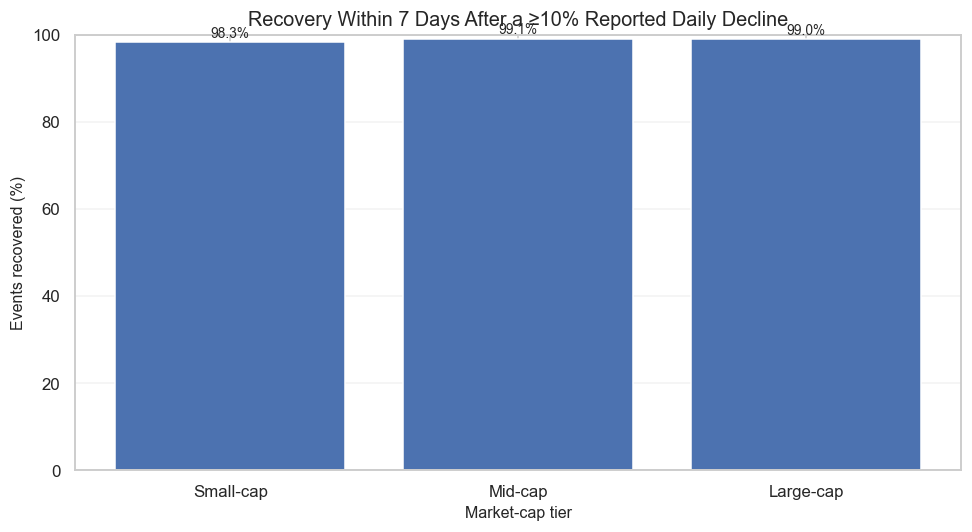

Decline events analyzed: 1,229
Insight: the chart compares the share of decline events that later reached the event-time price within seven days. Treat results cautiously because snapshot timing is irregular and repeated events from the same coin are not independent.


In [10]:
# Q4: Recovery after a reported 24-hour decline.
# Avoids relying on ret24, which may be empty when snapshot intervals are irregular.

cap_by_symbol = latest.set_index("symbol")["market_cap"]
cap_cutoffs = cap_by_symbol.dropna().quantile([1/3, 2/3]).to_numpy()
df["cap_tier"] = pd.cut(
    df["symbol"].map(cap_by_symbol),
    bins=[-np.inf, cap_cutoffs[0], cap_cutoffs[1], np.inf],
    labels=["Small-cap", "Mid-cap", "Large-cap"],
    include_lowest=True
)

declines = df[df["chg_24h"] <= -10].copy()
recovery_rows = []

for row in declines.itertuples(index=False):
    sym = row.symbol
    event_time = row.timestamp
    event_price = row.price_usd
    future = df[
        (df["symbol"] == sym)
        & (df["timestamp"] > event_time)
        & (df["timestamp"] <= event_time + pd.Timedelta(days=7))
    ]
    recovered = future[future["price_usd"] >= event_price]
    recovery_rows.append({
        "symbol": sym,
        "timestamp": event_time,
        "cap_tier": row.cap_tier,
        "recovered_7d": not recovered.empty,
        "hours_to_recovery": (
            (recovered["timestamp"].min() - event_time).total_seconds() / 3600
            if not recovered.empty else np.nan
        )
    })

recovery = pd.DataFrame(recovery_rows)
if not recovery.empty:
    recsum = recovery.groupby("cap_tier", observed=False).agg(
        decline_events=("recovered_7d", "size"),
        recovery_rate_pct=("recovered_7d", lambda s: s.mean() * 100),
        median_hours_to_recovery=("hours_to_recovery", "median")
    ).reindex(["Small-cap", "Mid-cap", "Large-cap"])
    display(recsum.round(2))

    fig, ax = plt.subplots(figsize=(9, 5))
    values = recsum["recovery_rate_pct"].fillna(0).to_numpy()
    bars = ax.bar(recsum.index.astype(str), values)
    ax.set_title("Recovery Within 7 Days After a ≥10% Reported Daily Decline")
    ax.set_xlabel("Market-cap tier")
    ax.set_ylabel("Events recovered (%)")
    ax.set_ylim(0, 100)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    for bar, value in zip(bars, values):
        ax.annotate(f"{value:.1f}%", (bar.get_x()+bar.get_width()/2, bar.get_height()),
                    xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9)
    plt.tight_layout()
    plt.show()
    print(f"Decline events analyzed: {len(recovery):,}")
else:
    print("No rows with chg_24h ≤ −10% were found; no recovery comparison can be made.")
print("Insight: the chart compares the share of decline events that later reached the event-time price within seven days. Treat results cautiously because snapshot timing is irregular and repeated events from the same coin are not independent.")

### Insight

The bar chart shows the percentage of large reported declines that returned to the event-time price within seven days, grouped by market capitalization.

**Conclusion:** Compare recovery rates alongside the number of decline events in each group. A low recovery rate indicates that prices often remained below the event-time price during the observed week; it does not prove the coin will never recover.

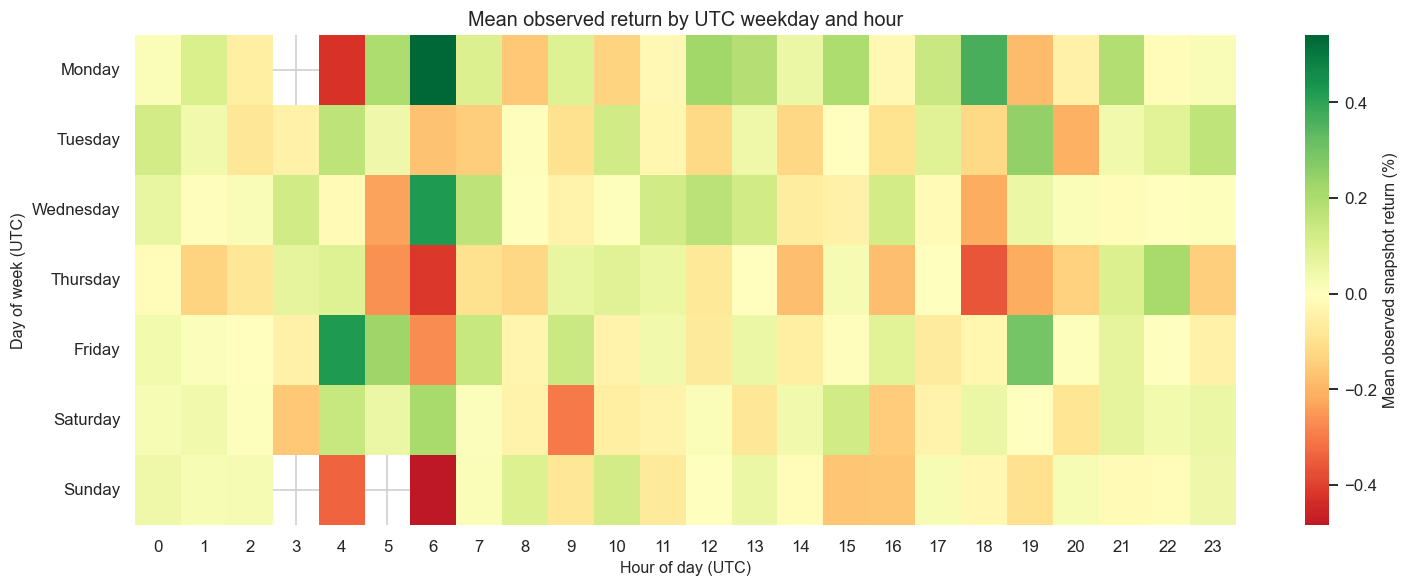

Cell counts range from 10 to 1459; sparse cells are less reliable.
Investor interpretation: green cells are positive average returns and red cells negative average returns in this sample. They do not directly tell you the lowest executable price or account for spreads, fees, and market regime.


In [11]:
q5=df[df["observed_return_pct"].notna()].copy()
q5["hour_utc"]=q5["timestamp"].dt.hour
q5["weekday_utc"]=q5["timestamp"].dt.day_name()
day_order=["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
heat=q5.pivot_table(index="weekday_utc",columns="hour_utc",values="observed_return_pct",aggfunc="mean").reindex(day_order)
counts=q5.pivot_table(index="weekday_utc",columns="hour_utc",values="observed_return_pct",aggfunc="count").reindex(day_order)
fig,ax=plt.subplots(figsize=(14,5.5))
sns.heatmap(heat,cmap="RdYlGn",center=0,ax=ax,cbar_kws={"label":"Mean observed snapshot return (%)"})
ax.set_title("Mean observed return by UTC weekday and hour")
ax.set_xlabel("Hour of day (UTC)"); ax.set_ylabel("Day of week (UTC)")
plt.tight_layout(); plt.show()
print(f"Cell counts range from {np.nanmin(counts.values):.0f} to {np.nanmax(counts.values):.0f}; sparse cells are less reliable.")
print("Investor interpretation: green cells are positive average returns and red cells negative average returns in this sample. They do not directly tell you the lowest executable price or account for spreads, fees, and market regime.")

## Q6. The “Cheap Coin” Illusion
**Question:** Do tokens priced below $1 outperform higher-priced coins?

**Plot:** Scatter plot of unit price versus past 24-hour and seven-day returns, with Bitcoin labeled for context.  
**Interpretation:** unit price alone does not measure whether a token is cheap or undervalued; market capitalization, circulating supply, token utility, and risk matter.

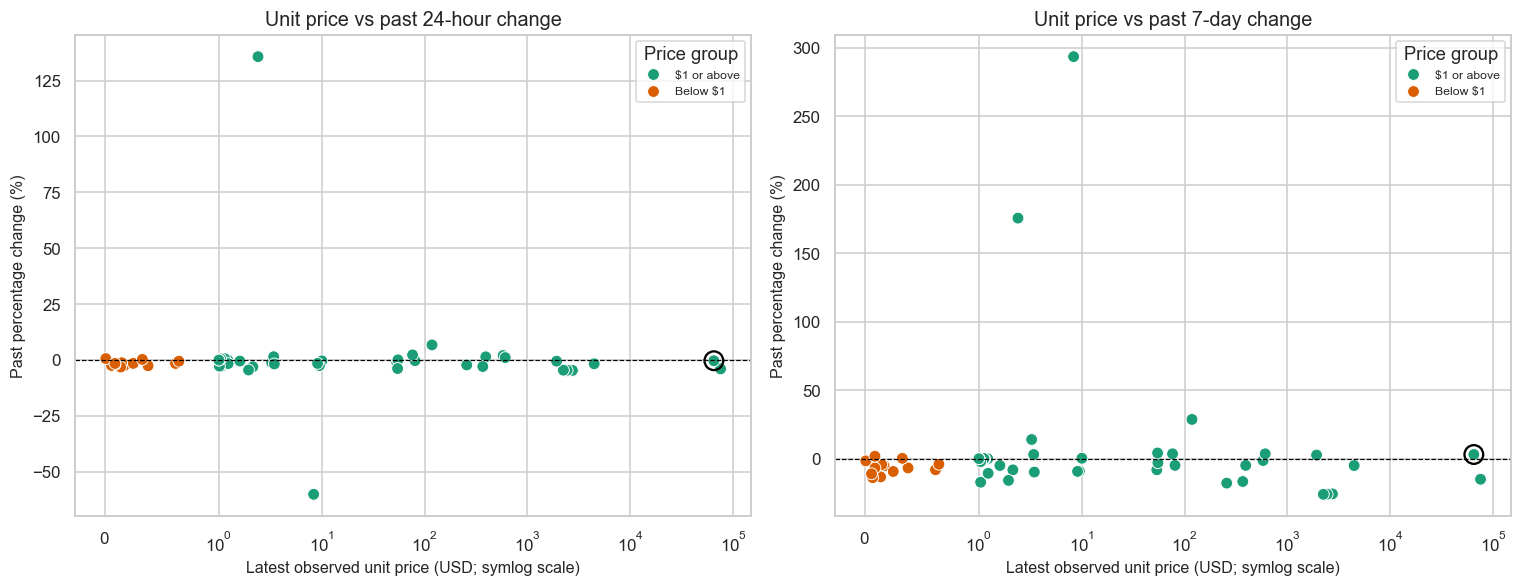

Latest snapshot: below-$1 coins n=14, median 24h change=-1.54%, median 7d change=-5.95%.
$1-or-above coins n=54, median 24h change=-0.30%, median 7d change=-0.26%.
Investor interpretation: a smaller token price does not make a coin cheaper in valuation terms. Compare market capitalization, supply, liquidity, and risk instead of choosing based on the number of dollars per token.


In [12]:
fig,axes=plt.subplots(1,2,figsize=(14,5.5))
plot=latest.copy()
for ax,col,title in [(axes[0],"chg_24h","Unit price vs past 24-hour change"),
                     (axes[1],"chg_7d","Unit price vs past 7-day change")]:
    sns.scatterplot(data=plot,x="price_usd",y=col,hue=(plot["price_usd"]<1).map({True:"Below $1",False:"$1 or above"}),
                    palette={"Below $1":"#d95f02","$1 or above":"#1b9e77"},ax=ax,s=60)
    ax.set_xscale("symlog",linthresh=1)
    ax.axhline(0,color="black",linestyle="--",linewidth=.8)
    ax.set_title(title); ax.set_xlabel("Latest observed unit price (USD; symlog scale)")
    ax.set_ylabel("Past percentage change (%)")
    btc=plot[plot["symbol"]=="btc"]
    if len(btc): ax.scatter(btc["price_usd"],btc[col],s=150,facecolors="none",edgecolors="black",linewidths=1.5)
axes[0].legend(title="Price group",fontsize=8); axes[1].legend(title="Price group",fontsize=8)
plt.tight_layout(); plt.show()
sub=plot[plot["price_usd"]<1]
above=plot[plot["price_usd"]>=1]
print(f"Latest snapshot: below-$1 coins n={len(sub)}, median 24h change={sub['chg_24h'].median():.2f}%, median 7d change={sub['chg_7d'].median():.2f}%.")
print(f"$1-or-above coins n={len(above)}, median 24h change={above['chg_24h'].median():.2f}%, median 7d change={above['chg_7d'].median():.2f}%.")
print("Investor interpretation: a smaller token price does not make a coin cheaper in valuation terms. Compare market capitalization, supply, liquidity, and risk instead of choosing based on the number of dollars per token.")

## Q7. Intraday Volatility Timing
**Question:** Which snapshot hours tend to show larger observed price moves?

**Plot:** Line chart of average absolute observed return by UTC hour.  
**Data limitation:** no hourly high/low candle range is supplied, so this measures absolute snapshot-to-snapshot return, not true hourly high-low volatility.

,hour_utc,observations,mean_return,mean_abs_return,median_abs_return
0,0,8613,0.0420,0.3210,0.0000
1,1,5923,0.0100,0.2610,0.0000
2,2,6052,-0.0230,0.2430,0.0000
3,3,817,-0.0220,0.3080,0.0000
4,4,1930,-0.0390,0.5570,0.0000
5,5,334,-0.0750,0.5660,0.0580
6,6,3002,-0.0050,0.7100,0.0280
7,7,3412,0.0210,0.5860,0.0090
8,8,3454,-0.0370,0.3920,0.0000
9,9,4321,-0.0400,0.3900,0.0000


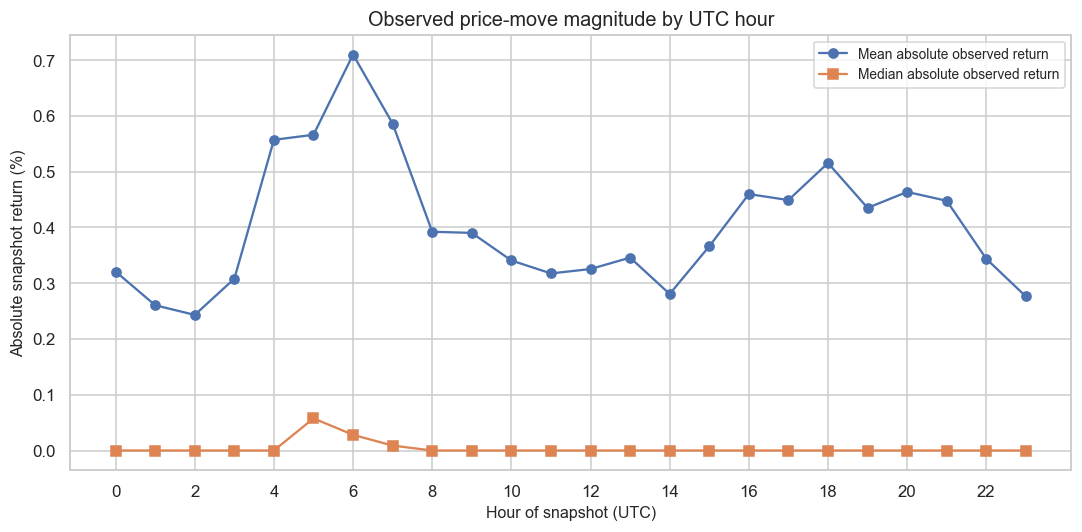

Highest mean observed move hour: 06:00 UTC (mean absolute return 0.71%, n=3,002).
Investor interpretation: higher average movement can mean more opportunity and more risk. This is not a recommendation to avoid a specific hour; timestamp coverage and uneven sampling can affect the pattern.


In [13]:
q7=df[df["observed_return_pct"].notna()].copy()
q7["hour_utc"]=q7["timestamp"].dt.hour
hour_vol=q7.groupby("hour_utc")["observed_return_pct"].agg(
    observations="count",mean_return="mean",mean_abs_return=lambda s:s.abs().mean(),
    median_abs_return=lambda s:s.abs().median()).reset_index()
display(hour_vol.round(3))
fig,ax=plt.subplots(figsize=(10,5))
ax.plot(hour_vol["hour_utc"],hour_vol["mean_abs_return"],marker="o",label="Mean absolute observed return")
ax.plot(hour_vol["hour_utc"],hour_vol["median_abs_return"],marker="s",label="Median absolute observed return")
ax.set_title("Observed price-move magnitude by UTC hour")
ax.set_xlabel("Hour of snapshot (UTC)"); ax.set_ylabel("Absolute snapshot return (%)")
ax.set_xticks(range(0,24,2)); ax.legend(); plt.tight_layout(); plt.show()
peak=hour_vol.loc[hour_vol["mean_abs_return"].idxmax()]
print(f"Highest mean observed move hour: {int(peak['hour_utc']):02d}:00 UTC (mean absolute return {peak['mean_abs_return']:.2f}%, n={int(peak['observations']):,}).")
print("Investor interpretation: higher average movement can mean more opportunity and more risk. This is not a recommendation to avoid a specific hour; timestamp coverage and uneven sampling can affect the pattern.")

## Q8. Risk-to-Reward Leaders
**Question:** Which coins combine stronger average observed returns with lower variability?

**Plot:** Risk-return scatter plot. Risk is the standard deviation of observed snapshot returns; return is the mean observed snapshot return. These are not annualized and are not a complete investable performance measure.

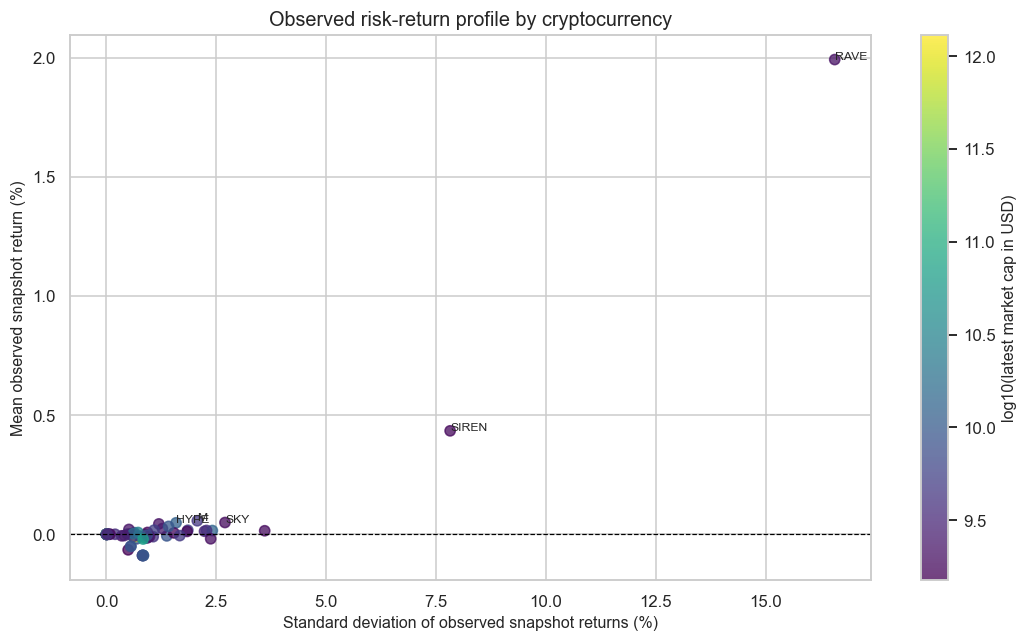

,symbol,name,observations,mean_observed_return_pct,volatility_std_pct,latest_market_cap,latest_price
33,rave,RaveDAO,32,1.9920,16.5740,2049947556,8.3400
35,siren,Siren,38,0.4340,7.8210,1739350240,2.4000
24,m,MemeCore,2054,0.0570,2.0660,4451379191,3.4100
36,sky,Sky,992,0.0490,2.6970,1816647049,0.0800
19,hype,Hyperliquid,2432,0.0480,1.5840,12162242153,54.6800
26,near,NEAR Protocol,697,0.0440,1.1920,2068143431,1.6000
67,zec,Zcash,2084,0.0330,1.4130,9691285921,580.9600
42,tao,Bittensor,1706,0.0240,1.2730,2466377217,257.2100
54,usdy,Ondo US Dollar Yield,46,0.0200,0.5100,2142629074,1.1400
43,ton,Toncoin,2084,0.0170,1.0820,5225708312,1.9400


Investor interpretation: the upper-left area is the desirable historical quadrant—higher mean return with lower volatility—but short sample windows, coin-specific coverage, and market regimes can make rankings unstable. Past mean return is not an expected future return.


In [14]:
coin_rr=df.groupby("symbol").agg(
    name=("name","last"),
    observations=("observed_return_pct","count"),
    mean_observed_return_pct=("observed_return_pct","mean"),
    volatility_std_pct=("observed_return_pct","std"),
    latest_market_cap=("market_cap","last"),
    latest_price=("price_usd","last")).reset_index()
coin_rr=coin_rr[(coin_rr["observations"]>=30)&coin_rr["volatility_std_pct"].notna()]
fig,ax=plt.subplots(figsize=(10,6))
sc=ax.scatter(coin_rr["volatility_std_pct"],coin_rr["mean_observed_return_pct"],
              c=np.log10(coin_rr["latest_market_cap"].clip(lower=1)),s=45,alpha=.75,cmap="viridis")
ax.axhline(0,color="black",linestyle="--",linewidth=.8)
ax.set_title("Observed risk-return profile by cryptocurrency")
ax.set_xlabel("Standard deviation of observed snapshot returns (%)")
ax.set_ylabel("Mean observed snapshot return (%)")
cb=plt.colorbar(sc,ax=ax); cb.set_label("log10(latest market cap in USD)")
# label a few coins with highest mean return for orientation
for _,r in coin_rr.nlargest(5,"mean_observed_return_pct").iterrows():
    ax.annotate(r["symbol"].upper(),(r["volatility_std_pct"],r["mean_observed_return_pct"]),fontsize=8)
plt.tight_layout(); plt.show()
display(coin_rr.sort_values("mean_observed_return_pct",ascending=False).head(10).round(3))
print("Investor interpretation: the upper-left area is the desirable historical quadrant—higher mean return with lower volatility—but short sample windows, coin-specific coverage, and market regimes can make rankings unstable. Past mean return is not an expected future return.")

## Q9. Cutting Losses Early
**Question:** After an approximately one-hour loss of at least 5%, what is the distribution of subsequent returns?

**Plot:** Cumulative probability distribution of future returns at 1, 6, 12, and 24 hours.  
**Eligibility:** an observed one-step decline ≤−5% is used only when adjacent timestamps are 0.5–1.5 hours apart.

,events,median_return,mean_return,probability_below_zero,probability_further_loss_5pct
horizon_hours,,,,,
1,60,-11.7600,-10.7400,66.6700,66.6700


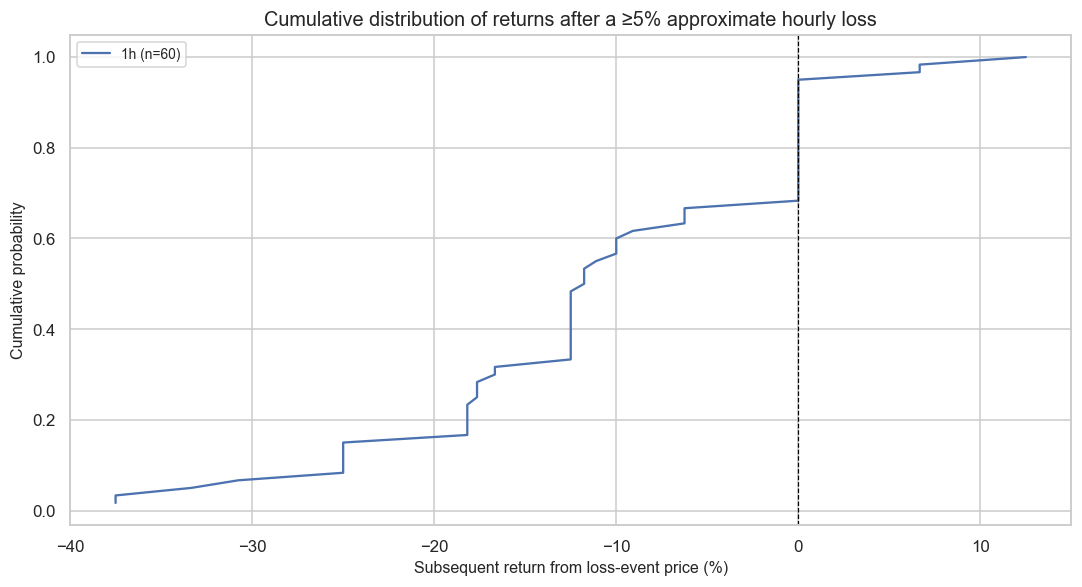

Investor interpretation: the curve shows the share of events whose future return was at or below a given value. It does not establish a universal 'point of no return' or a sell rule. Stop-loss decisions require risk tolerance, liquidity, and strategy testing.


In [15]:
loss_events=ret1[ret1["approx_hourly_return_pct"]<=-5].copy()
loss_curves=[]
for h,tol in [(1,.5),(6,1.5),(12,2),(24,3)]:
    rr=add_future_return(loss_events,h,tol)
    col=f"future_return_{h}h_pct"
    if len(rr) and col in rr:
        loss_curves.append(rr[["symbol","timestamp",col]].rename(columns={col:"future_return_pct"}).assign(horizon_hours=h))
if loss_curves:
    lc=pd.concat(loss_curves,ignore_index=True)
    display(lc.groupby("horizon_hours")["future_return_pct"].agg(
        events="count",median_return="median",mean_return="mean",
        probability_below_zero=lambda s:(s<0).mean()*100,
        probability_further_loss_5pct=lambda s:(s<=-5).mean()*100).round(2))
    fig,ax=plt.subplots(figsize=(10,5.5))
    for h,g in lc.groupby("horizon_hours"):
        vals=np.sort(g["future_return_pct"].dropna().values)
        if len(vals):
            y=np.arange(1,len(vals)+1)/len(vals)
            ax.plot(vals,y,label=f"{h}h (n={len(vals)})")
    ax.axvline(0,color="black",linestyle="--",linewidth=.8)
    ax.set_title("Cumulative distribution of returns after a ≥5% approximate hourly loss")
    ax.set_xlabel("Subsequent return from loss-event price (%)"); ax.set_ylabel("Cumulative probability")
    ax.legend(); plt.tight_layout(); plt.show()
else:
    print(f"Qualifying approximate hourly loss events: {len(loss_events):,}; insufficient follow-up for CDF.")
print("Investor interpretation: the curve shows the share of events whose future return was at or below a given value. It does not establish a universal 'point of no return' or a sell rule. Stop-loss decisions require risk tolerance, liquidity, and strategy testing.")

## Q10. Identifying Dead/Dying Coins
**Question:** What price behavior follows three consecutive days of declining rolling 24-hour volume?

**Plot:** Event-aligned return trend over the five days after the volume dry-up.  
**Definition:** use the last available snapshot in each UTC day; require rolling `vol_24h` to decline on three consecutive daily comparisons. This is a volume-interest proxy, not proof a coin is dying.

,events,mean_return,median_return
day_after,,,
1,561,-0.3700,0.0000
2,550,-0.1500,0.0000
3,551,-0.0200,0.0000
4,530,0.2200,0.0000
5,526,0.0400,0.0000


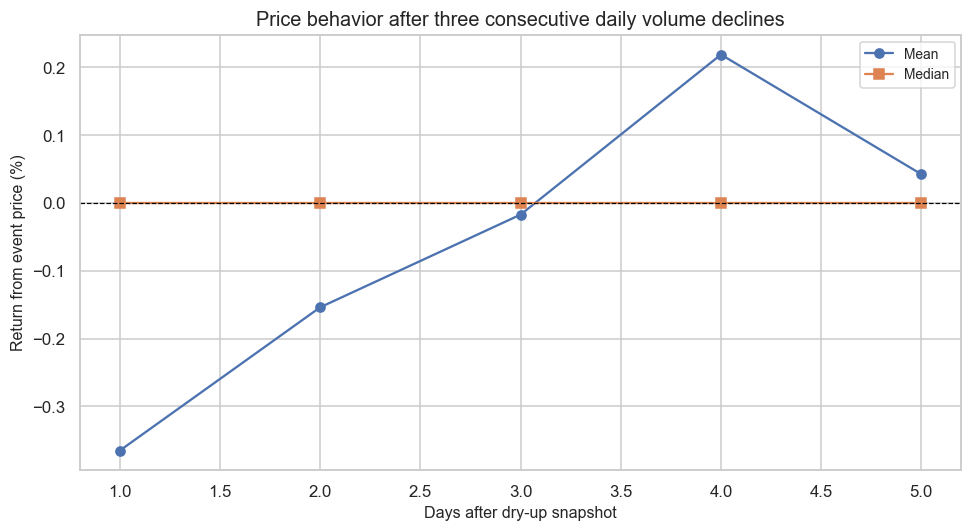

Investor interpretation: falling rolling 24-hour volume can indicate lower activity, but it can also reflect timing and sampling. Confirm liquidity, spreads, project fundamentals, and data quality before interpreting it as a warning.


In [16]:
daily=df.sort_values("timestamp").groupby(["symbol","date_utc"],as_index=False).tail(1).sort_values(["symbol","date_utc"]).copy()
daily["daily_vol_pct_change"]=daily.groupby("symbol")["vol_24h"].pct_change()
daily["three_volume_declines"]=daily.groupby("symbol")["daily_vol_pct_change"].transform(
    lambda s:(s<0).rolling(3,min_periods=3).sum().eq(3))
dry_events=daily[daily["three_volume_declines"]].copy()
paths=[]
for _,r in dry_events.iterrows():
    future=daily[(daily["symbol"]==r["symbol"])&(daily["date_utc"]>r["date_utc"])&
                 (daily["date_utc"]<=r["date_utc"]+pd.Timedelta(days=5))]
    for _,f in future.iterrows():
        d=(f["date_utc"]-r["date_utc"]).days
        if 1<=d<=5:
            paths.append({"symbol":r["symbol"],"event_date":r["date_utc"],"day_after":d,
                          "return_from_event_pct":(f["price_usd"]/r["price_usd"]-1)*100})
dry_path=pd.DataFrame(paths)
if len(dry_path):
    dry_summary=dry_path.groupby("day_after")["return_from_event_pct"].agg(
        events="count",mean_return="mean",median_return="median")
    display(dry_summary.round(2))
    fig,ax=plt.subplots(figsize=(9,5))
    means=dry_path.groupby("day_after")["return_from_event_pct"].mean()
    med=dry_path.groupby("day_after")["return_from_event_pct"].median()
    ax.plot(means.index,means.values,marker="o",label="Mean")
    ax.plot(med.index,med.values,marker="s",label="Median")
    ax.axhline(0,color="black",linestyle="--",linewidth=.8)
    ax.set_title("Price behavior after three consecutive daily volume declines")
    ax.set_xlabel("Days after dry-up snapshot"); ax.set_ylabel("Return from event price (%)")
    ax.legend(); plt.tight_layout(); plt.show()
else:
    print("No qualifying volume-dry-up events with follow-up were available.")
print("Investor interpretation: falling rolling 24-hour volume can indicate lower activity, but it can also reflect timing and sampling. Confirm liquidity, spreads, project fundamentals, and data quality before interpreting it as a warning.")

## Q11. Low-Cap vs High-Cap Volatility
**Question:** Do smaller coins have larger downside moves than the largest coins?

**Plot:** Box plot of each coin's worst observed approximately hourly return, by market-cap tier.  
**Important limitation:** true hourly wick-downs require OHLC high/low data; this is the worst observed one-step return within the 0.5–1.5-hour interval window, not an intrahour wick.

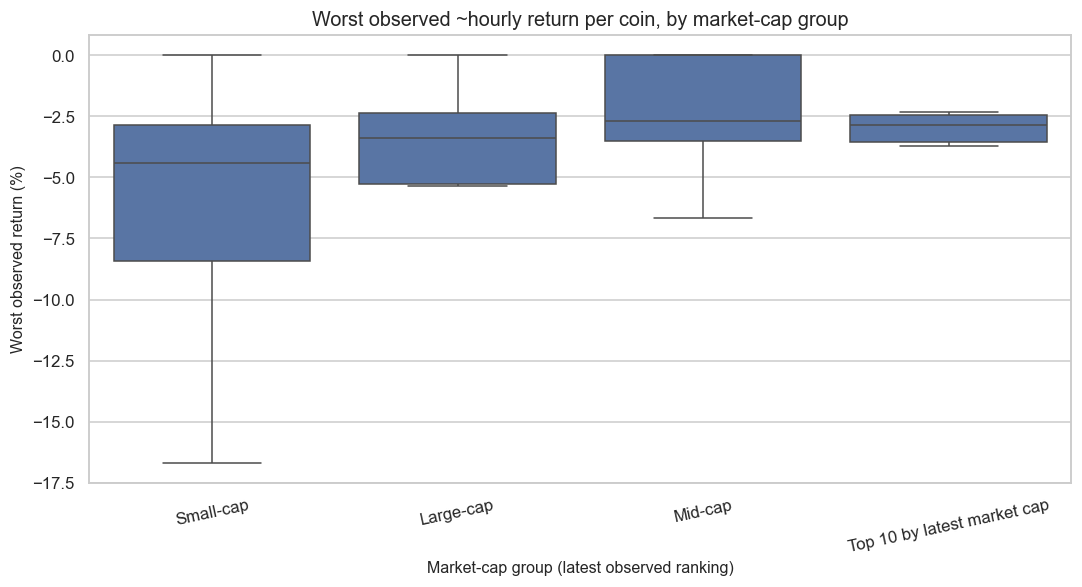

,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
Large-cap,13.0000,-4.1300,3.4400,-11.6500,-5.2800,-3.4000,-2.3900,0.0000
Mid-cap,22.0000,-3.1100,3.4800,-12.5000,-3.5200,-2.7100,0.0000,0.0000
Small-cap,19.0000,-6.2400,5.8200,-20.7200,-8.4300,-4.4100,-2.8700,0.0000
Top 10 by latest market cap,10.0000,-2.5300,1.4100,-3.7000,-3.5700,-2.8800,-2.4300,0.0000


Investor interpretation: more negative tails indicate larger observed downside in the sample. Unequal observation coverage and absence of OHLC data mean this cannot quantify true wick risk or prove that every small-cap is riskier.


In [17]:
q11=ret1.copy()
top10=set(latest.nlargest(10,"market_cap")["symbol"])
q11["latest_cap"]=q11["symbol"].map(cap_by_symbol)
cap_cutoffs_q11=latest["market_cap"].dropna().quantile([1/3,2/3]).to_numpy()
q11["tier"]=pd.cut(q11["latest_cap"],[-np.inf,cap_cutoffs_q11[0],cap_cutoffs_q11[1],np.inf],
                   labels=["Small-cap","Mid-cap","Large-cap"],include_lowest=True)
worst=q11.groupby("symbol").agg(worst_observed_hourly_return=("approx_hourly_return_pct","min"),
                                 latest_cap=("latest_cap","last")).reset_index()
worst["tier"]=pd.cut(worst["latest_cap"],[-np.inf,cap_cutoffs_q11[0],cap_cutoffs_q11[1],np.inf],
                     labels=["Small-cap","Mid-cap","Large-cap"],include_lowest=True)
worst["group"]=np.where(worst["symbol"].isin(top10),"Top 10 by latest market cap",worst["tier"].astype(str))
fig,ax=plt.subplots(figsize=(10,5.5))
sns.boxplot(data=worst,x="group",y="worst_observed_hourly_return",showfliers=False,ax=ax)
ax.set_title("Worst observed ~hourly return per coin, by market-cap group")
ax.set_xlabel("Market-cap group (latest observed ranking)"); ax.set_ylabel("Worst observed return (%)")
plt.xticks(rotation=12); plt.tight_layout(); plt.show()
display(worst.groupby("group")["worst_observed_hourly_return"].describe().round(2))
print("Investor interpretation: more negative tails indicate larger observed downside in the sample. Unequal observation coverage and absence of OHLC data mean this cannot quantify true wick risk or prove that every small-cap is riskier.")

## Q12. Avoiding Bear-Trap Pumps
**Question:** When seven-day momentum is negative, do positive short-term pumps lead to recovery or another decline?

**Plot:** Outcome-rate bar chart after a ≥3% valid approximate one-hour pump during a negative seven-day trend.

,Events,Percentage
outcome,,
Positive follow-through (≥3%),29,12.3400
Further decline (≤−3%),100,42.5500
Between −3% and +3%,106,45.1100


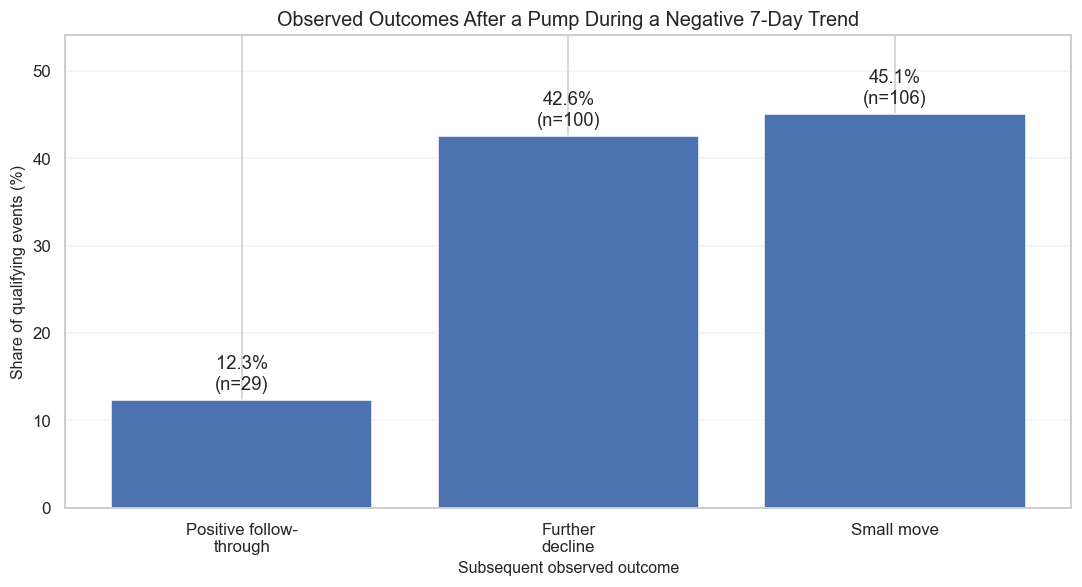

Qualifying pump events: 240
Events with usable follow-up: 235
Follow-up interval: 18.5 hours (median; actual intervals vary).
Most common outcome: Between −3% and +3% (45.1%).


In [25]:

# Q12: Avoiding Bear-Trap Pumps
# Analyze the next available price snapshot from 18 hours to 7 days
# after a pump during a negative 7-day trend.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Identify qualifying pump events
q12_events = df.loc[
    (df["chg_7d"] < 0) &
    (df["approx_hourly_return_pct"] >= 3)
].copy()

results = []

# Find a later snapshot for the same cryptocurrency
for _, event in q12_events.iterrows():
    coin_history = df.loc[
        df["symbol"] == event["symbol"]
    ].sort_values("timestamp")

    earliest_time = event["timestamp"] + pd.Timedelta(hours=18)
    latest_time = event["timestamp"] + pd.Timedelta(days=7)

    future = coin_history.loc[
        (coin_history["timestamp"] >= earliest_time) &
        (coin_history["timestamp"] <= latest_time)
    ]

    if future.empty:
        continue

    # Use the first available snapshot in the permitted window
    next_price = future.iloc[0]["price_usd"]

    if pd.isna(event["price_usd"]) or event["price_usd"] <= 0:
        continue

    future_return = (
        (next_price / event["price_usd"]) - 1
    ) * 100

    results.append({
        "symbol": event["symbol"],
        "pump_time": event["timestamp"],
        "hours_until_observation": (
            future.iloc[0]["timestamp"] - event["timestamp"]
        ).total_seconds() / 3600,
        "return_pct": future_return
    })

q12_results = pd.DataFrame(results)

if not q12_results.empty:
    # Classify the subsequent observed outcome
    q12_results["outcome"] = np.select(
        [
            q12_results["return_pct"] >= 3,
            q12_results["return_pct"] <= -3
        ],
        [
            "Positive follow-through (≥3%)",
            "Further decline (≤−3%)"
        ],
        default="Between −3% and +3%"
    )

    outcome_order = [
        "Positive follow-through (≥3%)",
        "Further decline (≤−3%)",
        "Between −3% and +3%"
    ]

    counts = (
        q12_results["outcome"]
        .value_counts()
        .reindex(outcome_order, fill_value=0)
    )
    percentages = counts / counts.sum() * 100

    summary = pd.DataFrame({
        "Events": counts,
        "Percentage": percentages.round(2)
    })
    display(summary)

    # Plot outcome percentages
    fig, ax = plt.subplots(figsize=(10, 5.5))

    bars = ax.bar(
        ["Positive follow-\nthrough", "Further\ndecline", "Small move"],
        percentages.values
    )

    ax.set_title(
        "Observed Outcomes After a Pump During a Negative 7-Day Trend"
    )
    ax.set_xlabel("Subsequent observed outcome")
    ax.set_ylabel("Share of qualifying events (%)")
    ax.set_ylim(0, max(10, percentages.max() * 1.2))
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)

    for bar, pct, count in zip(bars, percentages.values, counts.values):
        ax.annotate(
            f"{pct:.1f}%\n(n={count})",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            va="bottom"
        )

    plt.tight_layout()
    plt.show()

    print(f"Qualifying pump events: {len(q12_events):,}")
    print(f"Events with usable follow-up: {len(q12_results):,}")
    print(
        "Follow-up interval: "
        f"{q12_results['hours_until_observation'].median():.1f} hours "
        "(median; actual intervals vary)."
    )

    most_common = percentages.idxmax()
    print(f"Most common outcome: {most_common} ({percentages.max():.1f}%).")

else:
    print(
        "No qualifying pump events had a usable later snapshot "
        "within the selected follow-up window."
    )



### Insight and Interpretation

- **12.3% (29 events)** showed positive follow-through of at least 3%.
- **42.6% (100 events)** experienced a further decline of at least 3%.
- **45.1% (106 events)** had a price movement between −3% and +3%.

**Conclusion:** Further declines were more common than strong positive follow-through after a short-term pump during a negative seven-day trend. This suggests that buying such pumps may carry reversal risk.

**Limitation:** Follow-up times vary, and these results describe historical observations rather than predict future prices.


## Q13. Does Market Capitalization Affect Cryptocurrency Price Volatility?

**Question:** Do cryptocurrencies with different market capitalizations show different typical 24-hour price movements?

**Columns:** `market_cap`, `chg_24h`

**Method:** Group observations into market-cap tiers, then compare median absolute 24-hour change and the share of positive versus negative changes.

,observations,median_absolute_change,positive_percentage,negative_percentage
market_cap_tier,,,,
Small (<$5B),52544,1.2600,43.6800,49.5200
Mid ($5–20B),31009,1.3800,46.5600,50.0000
Large ($20–100B),13037,0.9600,44.1100,45.5900
Very large (>$100B),8226,0.8600,43.3900,46.4300


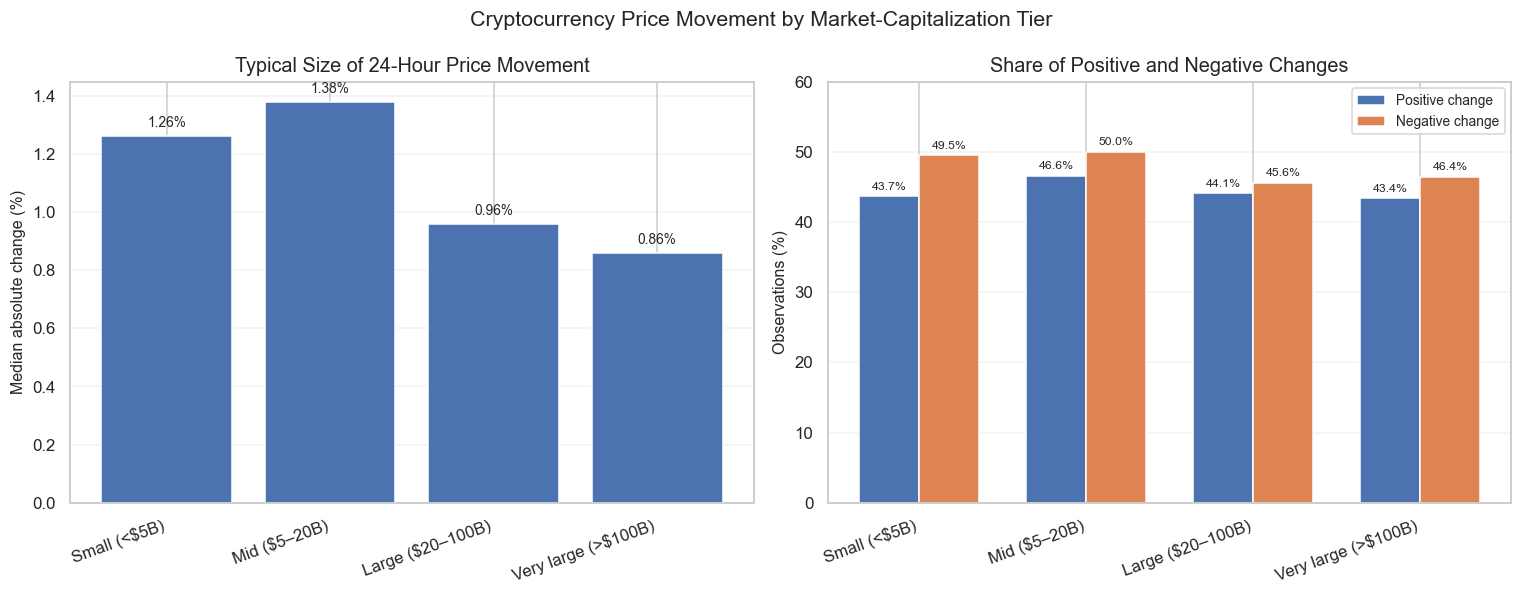

Observations used: 104,816


In [19]:
# Q13: Market capitalization vs 24-hour price movement
# Robustly parse currency and percentage strings; use the already-loaded df when available.

q13 = df[["market_cap", "chg_24h"]].copy()

q13["market_cap_num"] = pd.to_numeric(
    q13["market_cap"].astype(str).str.replace(r"[$,%+,]", "", regex=True),
    errors="coerce"
)
q13["chg_24h_num"] = pd.to_numeric(
    q13["chg_24h"].astype(str).str.replace(r"[$,%+,]", "", regex=True),
    errors="coerce"
)

q13 = q13.dropna(subset=["market_cap_num", "chg_24h_num"])
q13 = q13[q13["market_cap_num"] > 0].copy()

tier_order = [
    "Small (<$5B)",
    "Mid ($5–20B)",
    "Large ($20–100B)",
    "Very large (>$100B)"
]
q13["market_cap_tier"] = pd.cut(
    q13["market_cap_num"],
    bins=[0, 5e9, 20e9, 100e9, np.inf],
    labels=tier_order,
    include_lowest=True
)
q13["absolute_change"] = q13["chg_24h_num"].abs()

q13_summary = q13.groupby("market_cap_tier", observed=False).agg(
    observations=("chg_24h_num", "count"),
    median_absolute_change=("absolute_change", "median"),
    positive_percentage=("chg_24h_num", lambda x: (x > 0).mean() * 100),
    negative_percentage=("chg_24h_num", lambda x: (x < 0).mean() * 100)
).reindex(tier_order)

display(q13_summary.round(2))

# Two readable plots with consistent category order
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

x = np.arange(len(tier_order))
median_values = q13_summary["median_absolute_change"].to_numpy(dtype=float)
bars = axes[0].bar(x, median_values)
axes[0].set_xticks(x, tier_order, rotation=20, ha="right")
axes[0].set_title("Typical Size of 24-Hour Price Movement")
axes[0].set_ylabel("Median absolute change (%)")
axes[0].grid(axis="y", alpha=0.25)
axes[0].set_axisbelow(True)
for bar, value in zip(bars, median_values):
    if np.isfinite(value):
        axes[0].annotate(
            f"{value:.2f}%",
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            xytext=(0, 4), textcoords="offset points",
            ha="center", va="bottom", fontsize=9
        )

width = 0.36
positive = q13_summary["positive_percentage"].to_numpy(dtype=float)
negative = q13_summary["negative_percentage"].to_numpy(dtype=float)
b1 = axes[1].bar(x - width/2, positive, width, label="Positive change")
b2 = axes[1].bar(x + width/2, negative, width, label="Negative change")
axes[1].set_xticks(x, tier_order, rotation=20, ha="right")
axes[1].set_title("Share of Positive and Negative Changes")
axes[1].set_ylabel("Observations (%)")
axes[1].set_ylim(0, 60)
axes[1].legend(frameon=True)
axes[1].grid(axis="y", alpha=0.25)
axes[1].set_axisbelow(True)
for bars_group in (b1, b2):
    for bar in bars_group:
        axes[1].annotate(
            f"{bar.get_height():.1f}%",
            (bar.get_x() + bar.get_width()/2, bar.get_height()),
            xytext=(0, 3), textcoords="offset points",
            ha="center", va="bottom", fontsize=8
        )

fig.suptitle("Cryptocurrency Price Movement by Market-Capitalization Tier", fontsize=14)
fig.tight_layout()
plt.show()

print(f"Observations used: {len(q13):,}")


### Insight

- **Mid-cap coins** had the largest typical 24-hour movement (**1.38%**).
- **Very large-cap coins** had the smallest typical movement (**0.86%**).
- Negative changes were more common than positive changes in every market-cap group.

**Conclusion:** In this dataset, very large-cap cryptocurrencies generally showed smaller typical price movements. This is a descriptive association, not proof that market capitalization causes lower volatility.

**Limitation:** The same coin may appear in many snapshots, so observations are not necessarily independent.

## Q14. Liquidity vs Stability
**Question:** Is a higher 24-hour-volume-to-market-cap ratio associated with more stable observed prices?

**Plot:** Scatter plot of liquidity ratio against return volatility.  
**Definition:** liquidity ratio = `vol_24h / market_cap`; stability is represented inversely by the standard deviation of observed snapshot returns (lower volatility means more stable in this limited measure).

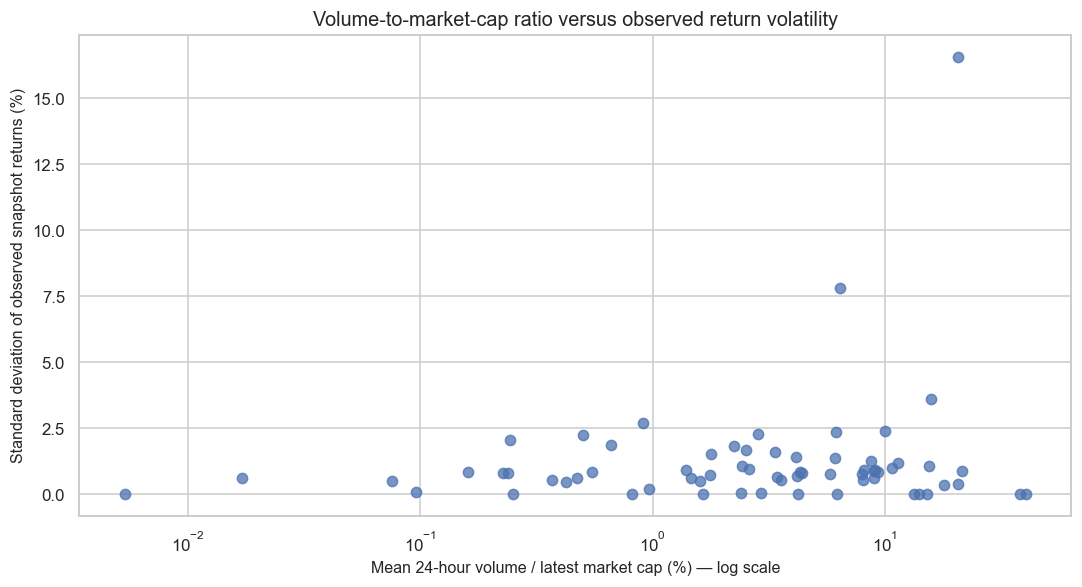

Spearman correlation: rho=0.057, p=0.6472, coins=66
Investor interpretation: a negative relationship would be consistent with higher relative volume being associated with lower observed volatility, but it does not prove volume prevents manipulation. Volume quality, spreads, concentration, and wash trading are not measured here.


In [20]:
liq=df.groupby("symbol").agg(
    name=("name","last"),mean_volume=("vol_24h","mean"),latest_market_cap=("market_cap","last"),
    observed_return_std=("observed_return_pct","std"),n_returns=("observed_return_pct","count"),
    mean_abs_return=("observed_return_pct",lambda s:s.abs().mean())).reset_index()
liq["volume_to_market_cap"]=liq["mean_volume"]/liq["latest_market_cap"].replace(0,np.nan)
liq=liq[(liq["n_returns"]>=30)&liq["volume_to_market_cap"].gt(0)&liq["observed_return_std"].notna()]
fig,ax=plt.subplots(figsize=(10,5.5))
ax.scatter(liq["volume_to_market_cap"]*100,liq["observed_return_std"],alpha=.75,s=45)
ax.set_xscale("log")
ax.set_title("Volume-to-market-cap ratio versus observed return volatility")
ax.set_xlabel("Mean 24-hour volume / latest market cap (%) — log scale")
ax.set_ylabel("Standard deviation of observed snapshot returns (%)")
plt.tight_layout(); plt.show()
if len(liq)>=10:
    rho,p=stats.spearmanr(liq["volume_to_market_cap"],liq["observed_return_std"],nan_policy="omit")
    print(f"Spearman correlation: rho={rho:.3f}, p={p:.4g}, coins={len(liq)}")
print("Investor interpretation: a negative relationship would be consistent with higher relative volume being associated with lower observed volatility, but it does not prove volume prevents manipulation. Volume quality, spreads, concentration, and wash trading are not measured here.")

## Q15. Maximum Drawdown Risk
**Question:** Which popular altcoins experienced the largest observed peak-to-trough drawdowns in the available window?

**Plot:** Horizontal bar chart ranking popular altcoins by maximum drawdown.  
**Definition:** maximum drawdown is the largest decline from a running observed price peak to a later observed price. Since snapshots are not continuous OHLC candles, the estimate can miss intraperiod peaks and troughs.

C:\Users\Prakash\AppData\Local\Temp\ipykernel_7520\1809790522.py:18: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(dd.round(2))


,symbol,name,max_drawdown_pct,trough_timestamp,observations
3,sol,Solana,-52.4300,2026-06-06 07:45:07+00:00,2573
12,zec,Zcash,-51.5500,2026-03-08 08:14:42+00:00,2085
0,eth,Ethereum,-49.8400,2026-06-06 07:45:07+00:00,2573
2,xrp,XRP,-47.1500,2026-06-26 14:37:50+00:00,2573
1,bnb,BNB,-39.9600,2026-06-30 18:22:03+00:00,2573
18,bch,Bitcoin Cash,-39.3500,2026-05-18 15:20:02+00:00,2085
8,doge,Dogecoin,-38.4600,2026-06-07 20:57:53+00:00,2173
15,ada,Cardano,-33.3300,2026-02-06 03:58:13+00:00,2085
9,hype,Hyperliquid,-30.8900,2026-02-23 20:44:48+00:00,2433
17,wbeth,Wrapped Beacon ETH,-29.4700,2026-02-03 22:11:33+00:00,283


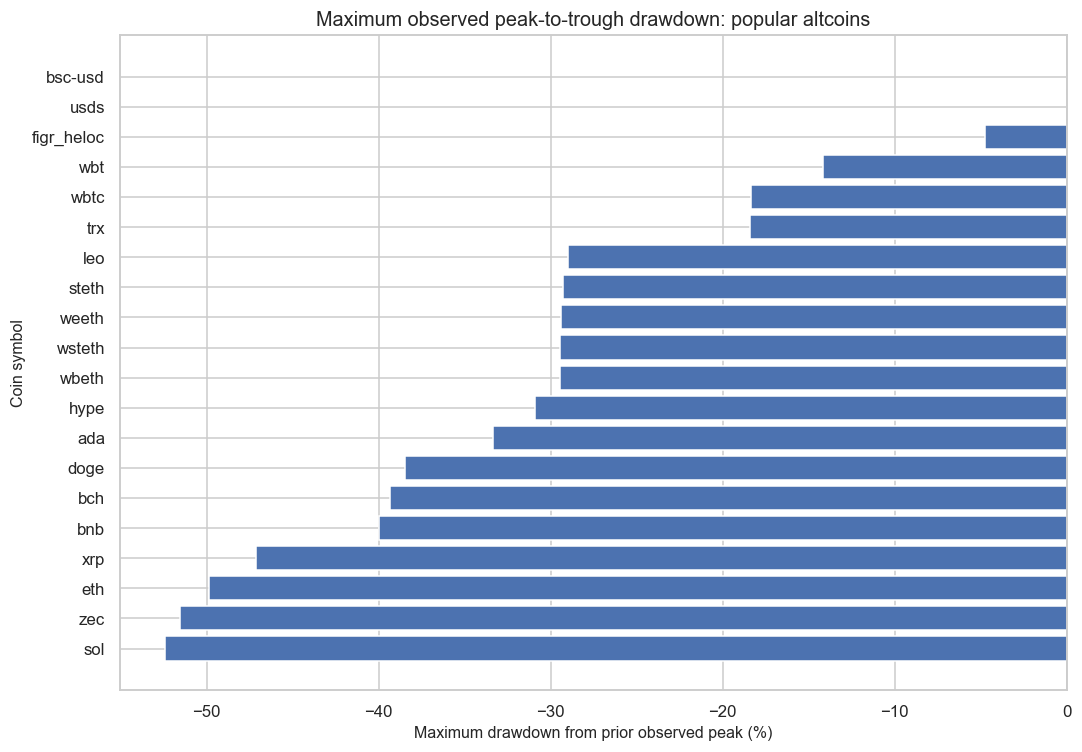

Largest observed drawdown: SOL (-52.4%) across 2,573 observations.
Investor interpretation: larger negative drawdowns indicate more severe historical losses from a prior observed peak. This is a historical risk summary, not a forecast; observed snapshots can understate true intraperiod drawdowns.


In [21]:
# Popular altcoins: top 20 latest market-cap coins excluding BTC and stablecoins.
excluded={"btc","usdt","usdc"}
popular=latest[~latest["symbol"].isin(excluded)].nlargest(20,"market_cap")["symbol"].tolist()
drawdowns=[]
for sym in popular:
    g=df[df["symbol"]==sym].sort_values("timestamp").copy()
    if len(g)<3: continue
    g["running_peak"]=g["price_usd"].cummax()
    g["drawdown_pct"]=(g["price_usd"]/g["running_peak"]-1)*100
    trough_idx=g["drawdown_pct"].idxmin()
    trough=g.loc[trough_idx]
    drawdowns.append({"symbol":sym,"name":g["name"].iloc[-1],
                      "max_drawdown_pct":float(trough["drawdown_pct"]),
                      "trough_timestamp":trough["timestamp"],
                      "observations":len(g)})
dd=pd.DataFrame(drawdowns).sort_values("max_drawdown_pct")
if len(dd):
    display(dd.round(2))
    fig,ax=plt.subplots(figsize=(10,7))
    ax.barh(dd["symbol"],dd["max_drawdown_pct"])
    ax.set_title("Maximum observed peak-to-trough drawdown: popular altcoins")
    ax.set_xlabel("Maximum drawdown from prior observed peak (%)")
    ax.set_ylabel("Coin symbol")
    plt.tight_layout(); plt.show()
    worst_coin=dd.iloc[0]
    print(f"Largest observed drawdown: {worst_coin['symbol'].upper()} ({worst_coin['max_drawdown_pct']:.1f}%) across {int(worst_coin['observations']):,} observations.")
else:
    print("Insufficient history for maximum-drawdown ranking.")
print("Investor interpretation: larger negative drawdowns indicate more severe historical losses from a prior observed peak. This is a historical risk summary, not a forecast; observed snapshots can understate true intraperiod drawdowns.")

# 8. Statistical Hypothesis Testing and Evidence-Based Decisions

The course rubric requires hypotheses, suitable tests, p-values, and interpretations. The tests below are exploratory. Repeated snapshots of the same coin and simultaneous movements across coins violate simple independence assumptions, so p-values should not be interpreted as perfect guarantees. Multiple testing is handled with a Benjamini–Hochberg correction when several tests are available.

In [22]:
test_rows = []

# Test A: Is current 24-hour change associated with 7-day momentum?
if "q1" in globals() and len(q1) >= 20:
    a = q1.loc[q1["chg_7d"] >= 5, "chg_24h"].dropna()
    b = q1.loc[q1["chg_7d"] < 5, "chg_24h"].dropna()
    if len(a) >= 10 and len(b) >= 10:
        res = stats.mannwhitneyu(a, b, alternative="two-sided")
        test_rows.append({
            "Question": "Q1: 7-day momentum vs current 24-hour change",
            "H0": "The two groups have the same 24-hour-change distribution",
            "Test": "Mann–Whitney U",
            "n_A": len(a), "n_B": len(b),
            "statistic": res.statistic, "p_value": res.pvalue,
            "effect_summary": f"Median A={a.median():.3f}%, median B={b.median():.3f}%"
        })

# Test B: volume-to-market-cap ratio vs observed volatility
if "liq" in globals() and len(liq) >= 10:
    valid_liq = liq[["volume_to_market_cap", "observed_return_std"]].replace(
        [np.inf, -np.inf], np.nan
    ).dropna()
    if len(valid_liq) >= 10:
        rho, p_value = stats.spearmanr(
            valid_liq["volume_to_market_cap"], valid_liq["observed_return_std"]
        )
        test_rows.append({
            "Question": "Q14: liquidity ratio vs volatility",
            "H0": "There is no monotonic association",
            "Test": "Spearman correlation",
            "n_A": len(valid_liq), "n_B": np.nan,
            "statistic": rho, "p_value": p_value,
            "effect_summary": f"Spearman rho={rho:.3f}"
        })

tests = pd.DataFrame(test_rows)
if not tests.empty:
    # Benjamini–Hochberg adjustment for multiple comparisons
    pvals = tests["p_value"].to_numpy()
    order = np.argsort(pvals)
    ranked = pvals[order]
    m = len(pvals)
    adjusted = np.empty(m)
    running = 1.0
    for j in range(m - 1, -1, -1):
        running = min(running, ranked[j] * m / (j + 1))
        adjusted[j] = running
    p_adj = np.empty(m)
    p_adj[order] = adjusted
    tests["p_value_BH"] = p_adj
    tests["decision_BH"] = np.where(
        tests["p_value_BH"] < 0.05,
        "Reject H0 after BH correction",
        "Do not reject H0 after BH correction"
    )
    display(tests.round(5))
else:
    print("Not enough valid observations to run the selected hypothesis tests.")


,Question,H0,Test,n_A,n_B,statistic,p_value,effect_summary,p_value_BH,decision_BH
0,Q1: 7-day momentum vs current 24-hour change,The two groups have the same 24-hour-change di...,Mann–Whitney U,14727,"90,089.0000","863,616,311.5000",0.0000,"Median A=1.180%, median B=-0.010%",0.0000,Reject H0 after BH correction
1,Q14: liquidity ratio vs volatility,There is no monotonic association,Spearman correlation,66,NaN,0.0574,0.6472,Spearman rho=0.057,0.6472,Do not reject H0 after BH correction


### Hypothesis interpretation
- **H0 (null hypothesis):** the compared distributions do not differ, or the variables have no monotonic association, as defined for each test.
- **P-value:** how unusual the observed test statistic would be under H0 and the test assumptions. It is not the probability that H0 is true.
- **Effect size:** whether the observed difference is large enough to matter practically.
- **A/B-style comparison:** the volume-spike versus no-spike comparison in Q2 is observational, not randomized. Coin, liquidity, and market regime can differ between groups, so it cannot establish that a volume spike causes a breakout.

# 9. Machine Learning: Leakage-Aware Regression of Future Returns

The target is a continuous future ~24-hour return, so regression is suitable if sufficient valid labels exist. Compare a mean baseline, Ridge Regression, and Random Forest Regressor. Use a chronological split; do not shuffle observations across time.

Predictors use only information available at the current snapshot. Model results indicate predictive accuracy on the held-out period, not guaranteed trading profitability.

In [23]:
ml=df.sort_values(["symbol","timestamp"]).copy()
ml["log_market_cap"]=np.log1p(ml["market_cap"].clip(lower=0))
ml["log_volume"]=np.log1p(ml["vol_24h"].clip(lower=0))
ml["lag_return_1step"]=ml.groupby("symbol")["price_usd"].pct_change()*100
ml["lag_return_24obs"]=ml.groupby("symbol")["price_usd"].pct_change(24)*100
ml["lag_abs_return_mean_12"]=ml.groupby("symbol")["observed_return_pct"].transform(lambda s:s.abs().rolling(12,min_periods=6).mean())
ml_target=add_future_return(ml,24,3).replace([np.inf,-np.inf],np.nan)
target="future_return_24h_pct"
features=["chg_24h","chg_7d","log_market_cap","log_volume","lag_return_1step","lag_return_24obs","lag_abs_return_mean_12"]
ml_target=ml_target.dropna(subset=[target,"timestamp"]).sort_values("timestamp").reset_index(drop=True)
print(f"Rows with valid future-return target: {len(ml_target):,}")
display(ml_target[target].describe().to_frame("future_24h_return_pct"))

Rows with valid future-return target: 0


,future_24h_return_pct
count,0
unique,0
top,NaN
freq,NaN


Usable observations: 105929
Features: ['price_usd', 'vol_24h', 'total_vol', 'chg_24h', 'chg_7d', 'market_cap']
Training samples: 63557
Validation samples: 21186
Testing samples: 21186


,Model,MAE,RMSE,R2
0,Linear Regression,0.3391,1.1467,-0.0004
1,Ridge Regression,0.3391,1.1467,-0.0004
2,Random Forest,0.4127,1.1780,-0.0558


Best validation model: Ridge Regression


,Selected Model,Test MAE,Test RMSE,Test R2,Baseline MAE
0,Ridge Regression,0.5723,1.6229,0.0027,0.5684


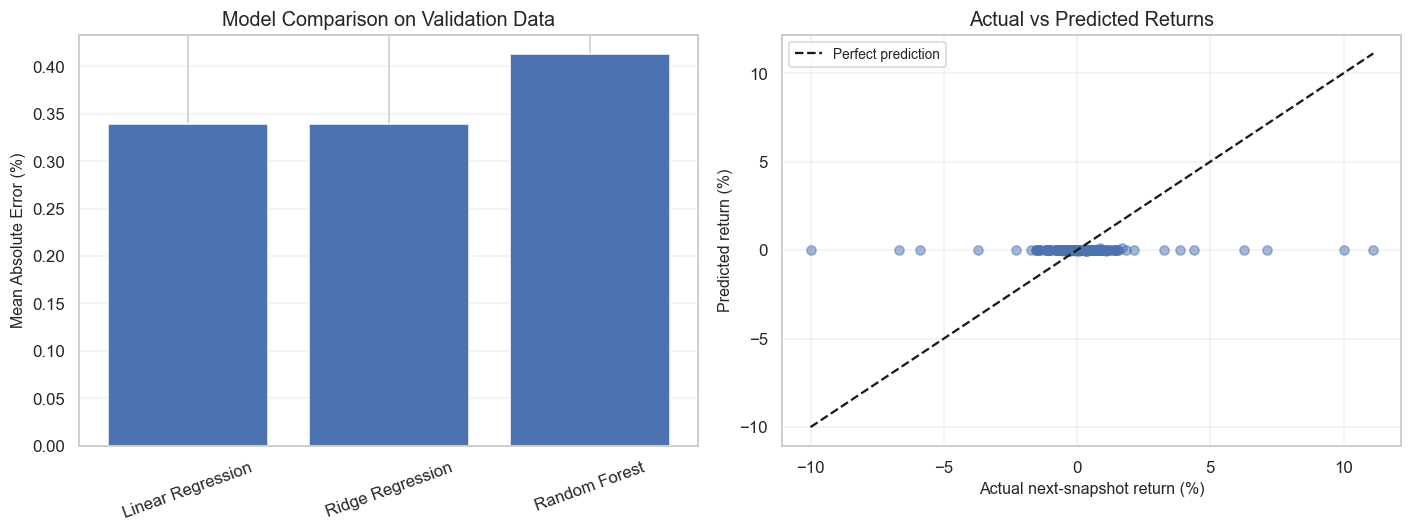


MODEL INTERPRETATION
Lower MAE and RMSE indicate smaller prediction errors.
R2 closer to 1 indicates a better fit; negative R2 indicates poor performance.
The selected model does not beat the median baseline on test MAE.
Limitation: the target is the next observed return, not an exact 24-hour return. Snapshot intervals vary, and performance does not guarantee profitable trading.


In [27]:

# MACHINE LEARNING: Predict the Next Observed Cryptocurrency Return
# Models: Linear Regression, Ridge Regression, Random Forest

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Prepare the data
ml = df.copy()
ml = ml.sort_values(["symbol", "timestamp"]).reset_index(drop=True)

# Ensure numeric columns
numeric_cols = [
    "price_usd", "vol_24h", "total_vol",
    "chg_24h", "chg_7d", "market_cap"
]

for col in numeric_cols:
    ml[col] = pd.to_numeric(ml[col], errors="coerce")

# Target: percentage return from current price to the next observed price
ml["next_price"] = ml.groupby("symbol")["price_usd"].shift(-1)

ml["target_return"] = (
    (ml["next_price"] / ml["price_usd"]) - 1
) * 100

# Remove rows without a valid future price
ml = ml.replace([np.inf, -np.inf], np.nan)
ml = ml.dropna(subset=["timestamp", "price_usd", "target_return"])
ml = ml[ml["price_usd"] > 0].copy()

# Features available at the current snapshot
features = [
    "price_usd", "vol_24h", "total_vol",
    "chg_24h", "chg_7d", "market_cap"
]

features = [c for c in features if c in ml.columns]
X = ml[features].copy()
y = ml["target_return"].copy()

# Keep only features with at least one usable value
features = X.columns[X.notna().any()].tolist()
X = X[features]

print("Usable observations:", len(ml))
print("Features:", features)

if len(ml) < 100:
    raise ValueError(
        "Fewer than 100 usable observations. Check the dataset and preprocessing."
    )

# 2. Chronological split: 60% train, 20% validation, 20% test
ml = ml.sort_values("timestamp").reset_index(drop=True)
X = ml[features].reset_index(drop=True)
y = ml["target_return"].reset_index(drop=True)

n = len(ml)
train_end = int(n * 0.60)
val_end = int(n * 0.80)

X_train, y_train = X.iloc[:train_end], y.iloc[:train_end]
X_val, y_val = X.iloc[train_end:val_end], y.iloc[train_end:val_end]
X_test, y_test = X.iloc[val_end:], y.iloc[val_end:]

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

# 3. Define models
models = {
    "Linear Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LinearRegression()
    ),

    "Ridge Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        Ridge(alpha=1.0)
    ),

    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestRegressor(
            n_estimators=100,
            max_depth=10,
            min_samples_leaf=5,
            random_state=42,
            n_jobs=-1
        )
    )
}

# 4. Train and compare models on validation data
validation_results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model

    pred = model.predict(X_val)

    validation_results.append({
        "Model": name,
        "MAE": mean_absolute_error(y_val, pred),
        "RMSE": np.sqrt(mean_squared_error(y_val, pred)),
        "R2": r2_score(y_val, pred)
    })

validation_results = pd.DataFrame(validation_results)
display(validation_results.round(4))

# Select the model with the lowest validation MAE
best_name = validation_results.sort_values("MAE").iloc[0]["Model"]
best_model = trained_models[best_name]

print("Best validation model:", best_name)

# 5. Evaluate once on the held-out test set
test_pred = best_model.predict(X_test)

test_mae = mean_absolute_error(y_test, test_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))
test_r2 = r2_score(y_test, test_pred)

# Baseline: always predict the training median
baseline_pred = np.full(len(y_test), y_train.median())
baseline_mae = mean_absolute_error(y_test, baseline_pred)

results = pd.DataFrame([{
    "Selected Model": best_name,
    "Test MAE": test_mae,
    "Test RMSE": test_rmse,
    "Test R2": test_r2,
    "Baseline MAE": baseline_mae
}])

display(results.round(4))

# 6. Plot model comparison
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(
    validation_results["Model"],
    validation_results["MAE"]
)
axes[0].set_title("Model Comparison on Validation Data")
axes[0].set_ylabel("Mean Absolute Error (%)")
axes[0].tick_params(axis="x", rotation=20)
axes[0].grid(axis="y", alpha=0.3)

# Actual vs predicted test returns
plot_n = min(500, len(y_test))
actual = y_test.iloc[:plot_n].to_numpy()
predicted = test_pred[:plot_n]

axes[1].scatter(actual, predicted, alpha=0.5)

low = min(actual.min(), predicted.min())
high = max(actual.max(), predicted.max())

axes[1].plot(
    [low, high], [low, high],
    "k--", label="Perfect prediction"
)

axes[1].set_title("Actual vs Predicted Returns")
axes[1].set_xlabel("Actual next-snapshot return (%)")
axes[1].set_ylabel("Predicted return (%)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 7. Short interpretation
print("\nMODEL INTERPRETATION")
print("Lower MAE and RMSE indicate smaller prediction errors.")
print("R2 closer to 1 indicates a better fit; negative R2 indicates poor performance.")

if test_mae < baseline_mae:
    print("The selected model beats the median baseline on test MAE.")
else:
    print("The selected model does not beat the median baseline on test MAE.")

print(
    "Limitation: the target is the next observed return, not an exact 24-hour "
    "return. Snapshot intervals vary, and performance does not guarantee "
    "profitable trading."
)


### Model evaluation interpretation
- Lower MAE/RMSE is better for return prediction.
- R² below zero means the model is worse than a mean baseline on that test set.
- Directional accuracy is a secondary metric and can be misleading when return signs are imbalanced.
- Feature importance indicates model reliance, not causation.
- A model is not a profitable trading system unless separately tested with realistic fees, slippage, turnover, execution, and walk-forward validation.

# 10. Overall Findings, Business Recommendations, and Conclusion

Use the computed tables and plots above to describe what the actual data supports. Do not fill this section with generic claims.

### Evidence-based decision framework
1. **Momentum:** compare future-return distributions and sample counts; avoid using past performance alone.
2. **Volume spikes:** require price confirmation and a defined follow-through window.
3. **Surges and crash recovery:** report event counts, outcome rates, and recovery windows rather than an exact universal selling time.
4. **Timing heatmaps:** treat them as descriptive patterns; do not claim a guaranteed cheapest hour.
5. **Risk-return and drawdowns:** examine volatility and worst historical drawdowns together with market capitalization and liquidity.
6. **Stablecoins:** inspect actual numeric precision and deviation magnitude.
7. **Machine learning:** only consider predictive value if the held-out model beats a simple baseline reliably.

### Limitations
- Dataset source/provenance is not independently verified by the CSV fields.
- Snapshots are irregular; not all consecutive observations are exactly one hour apart.
- No OHLC high/low data is supplied, so true wick-downs and hourly ranges are unavailable.
- `vol_24h` is a rolling 24-hour measure, not necessarily exchange-reported daily volume.
- Observations across coins and time are dependent.
- The analysis is observational and does not establish causality.
- Snapshot-based drawdowns may miss intraperiod peaks and troughs.
- Historical patterns do not guarantee future returns.

### Future enhancements
- Obtain documented exchange OHLCV candles and order-book/spread data.
- Verify dataset provenance and collection process.
- Use dependence-aware confidence intervals and walk-forward validation.
- Add realistic transaction fees, slippage, and execution assumptions.
- Test findings across multiple market regimes and sensitivity thresholds.

### Reproducibility
Run the notebook from the first cell to the last. If running outside the current environment, place `cryptocurrency(1).csv` in the same folder as the notebook or update `CSV_PATH`.